# Making a Viterbi Physics Backbone

In [75]:
import os
import glob
import numpy as np
np.random.seed(1234213423)
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.image as mpimg

import re
import warnings
warnings.filterwarnings('ignore')

In [76]:
# Automatically detect if running on Kaggle or Locally
IS_KAGGLE = os.path.exists('/kaggle/input')
BASE_DIR = '/kaggle/input/competitions/rogii-wellbore-geology-prediction' if IS_KAGGLE else '../data'

print(f"Running on {'Kaggle' if IS_KAGGLE else 'Local Environment'}")
print(f"Data Directory: {BASE_DIR}")
train_data = os.path.join(BASE_DIR, "train")
file_paths = sorted(os.listdir(train_data))

# Regex pattern: 
pattern = re.compile(r'([^/\\]+)__horizontal_well\.csv')

well_names = []
for path in file_paths:
    match = pattern.search(path)
    if match:
        well_names.append(match.group(1))

print("Extracted Well Names:")
print(len(well_names), "Well Names")

Running on Local Environment
Data Directory: ../data
Extracted Well Names:
773 Well Names


## Pre Processing

In [77]:
from scipy.signal import butter, filtfilt
from scipy.stats import pearsonr
from scipy.signal import savgol_filter

HW_LOW_PASS_CUTOFF = 0.009
def remove_rotation_noise(gr_series, cutoff=HW_LOW_PASS_CUTOFF):
    """Low pass filter."""
    gr_filled = gr_series.interpolate(method='linear').bfill().ffill()
    nyquist = 0.5 
    normal_cutoff = cutoff / nyquist
    b, a = butter(1, normal_cutoff, btype='low', analog=False)
    return filtfilt(b, a, gr_filled)

def pre_process(well):
    hw = pd.read_csv(train_data + f"/{well}__horizontal_well.csv")
    tw = pd.read_csv(train_data + f"/{well}__typewell.csv")

    mask = np.isnan(hw['TVT_input'].values)
    evalz = hw[mask]
    known = hw[~mask].copy().sort_values(by='TVT_input')
    tvt0 = hw[~mask]['TVT_input'].iloc[-1]

    # Z
    m_z, c_z = np.polyfit(evalz['MD'], evalz['Z'], deg=1)
    z = (m_z * evalz['MD'].values + c_z) - evalz['Z'].values

    # Evalz - GR
    # m_gr, c_gr = np.polyfit(remove_rotation_noise(known['GR']), np.interp(known['TVT_input'], tw['TVT'], tw['GR']), deg=1)
    gr = remove_rotation_noise(evalz['GR']) #* m_gr + c_gr

    # TW
    tw_tvt = tw['TVT'].values
    tw_gr = tw['GR'].values
    
    return z, gr, tvt0, tw_gr, tw_tvt, 
    

## Finding the correct trajectory

In [78]:
def find_ms(boundaries, z, gr, tvt0, tw_gr, tw_tvt):

    global anchors
    # Anchors for chunk = (Z+TVT)_0 + m * MD
    initial_anchor = -z[0] # Z + TVT, TVT_pred[0] is 0
    anchors = [np.array([initial_anchor])]

    
    for i in range(1, len(boundaries)):
        current_md_steps = boundaries[i]
        min_anchor = initial_anchor + (-max_m_range * current_md_steps)
        max_anchor = initial_anchor + (max_m_range * current_md_steps)
        
        num_candidates = (max_anchor - min_anchor) * anchor_density
        num_candidates = max(int(num_candidates), 1)
        
        anchors.append(np.linspace(min_anchor, max_anchor, num_candidates))

    global costs
    global tvt0s
    global slopes
    global backpointer
    
    costs = [np.full(len(cands), np.inf) for cands in anchors]
    tvt0s = [np.full(len(cands), np.inf) for cands in anchors]
    slopes = [np.zeros(len(cands)) for cands in anchors]
    backpointer = [np.zeros(len(cands), dtype=int) for cands in anchors]
    costs[0][0] = 0.0
    tvt0s[0][0] = tvt0
    
    # ==========================================
    # 2. VECTORIZED VITERBI FORWARD PASS
    # ==========================================
    for i in range(num_chunks):
        start_idx = boundaries[i]
        end_idx = boundaries[i+1]
        chunk_len = end_idx - start_idx
        
        steps = np.arange(chunk_len)
        chunk_z = z[start_idx:end_idx]
        chunk_gr = gr[start_idx:end_idx]
    
        # Target arrays for current and next anchors
        curr_anchors = anchors[i]
        next_anchors = anchors[i+1]
        N = len(curr_anchors)
        M = len(next_anchors)
    
        # 1. Compute all possible slopes simultaneously (M matrix)
        # Shape: (N, M)
        M_mat = (next_anchors[None, :] - curr_anchors[:, None]) / chunk_len
        
        # 2. Identify valid paths (base cost not inf, slope within bounds)
        # Shape: (N, M)
        valid_mask = (costs[i][:, None] != np.inf) & (np.abs(M_mat) <= max_m)
        
        # Extract 1D indices mapping the valid combinations
        valid_curr_k, valid_next_k = np.where(valid_mask)
        num_valid = len(valid_curr_k)
        
        if num_valid > 0:
            # 3. Filter down to valid variables and reshape for 2D broadcasting
            # Shape: (num_valid, 1)
            v_curr_anchors = curr_anchors[valid_curr_k][:, None]
            v_m = M_mat[valid_curr_k, valid_next_k][:, None]
            steps_2d = steps[None, :]
            
            # 4. Simulate trajectory strictly for valid paths
            # Shape: (num_valid, chunk_len)
            v_hypo_z_tvt = v_curr_anchors + (v_m * steps_2d)
            v_hypo_tvt = v_hypo_z_tvt + chunk_z[None, :] + tvt0
            
            # 5. Interpolate Type Well GR (flatten for 1D interp, reshape back)
            # Shape: (num_valid, chunk_len)
            v_pred_gr = np.interp(v_hypo_tvt.ravel(), tw_tvt, tw_gr).reshape(num_valid, chunk_len)
            
            # 6. Vectorized Cost Functions
            # Pure Shape Matching (MSE): Shape (num_valid,)
            v_chunk_cost = np.sum((chunk_gr[None, :] - v_pred_gr)**2, axis=1)
            
            # TVT deviation limit: Shape (num_valid,)
            v_curr_tvt0 = tvt0s[i][valid_curr_k][:, None]
            v_tvt_deviation = beta * (np.sum((v_hypo_tvt - v_curr_tvt0)**2, axis=1) / (chunk_len**2))

            v_m_penalty = gamma * chunk_len * (v_m.ravel() ** 2)
            
            # Summing the raw matching costs: Shape (num_valid,)
            v_base_cost = costs[i][valid_curr_k]
            v_total_cost = v_base_cost + v_chunk_cost + v_tvt_deviation + v_m_penalty
            
            # 7. Map the 1D flat valid costs back into an N x M transition grid
            total_cost_matrix = np.full((N, M), np.inf)
            total_cost_matrix[valid_curr_k, valid_next_k] = v_total_cost
            
            # Locate the cheapest incoming path for each anchor in the next boundary
            min_indices = np.argmin(total_cost_matrix, axis=0) # Shape: (M,)
            min_costs = np.min(total_cost_matrix, axis=0)      # Shape: (M,)
            
            # 8. Update target arrays via mask if the new path is strictly cheaper
            update_mask = min_costs < costs[i+1]
            
            if np.any(update_mask):
                target_cols = np.where(update_mask)[0]
                source_rows = min_indices[update_mask]
                
                costs[i+1][update_mask] = min_costs[update_mask]
                slopes[i+1][update_mask] = M_mat[source_rows, target_cols]
                backpointer[i+1][update_mask] = source_rows
                
                # Compute the last hypo_tvt entirely mathematically for the winning paths
                winning_curr_anchors = curr_anchors[source_rows]
                winning_m = M_mat[source_rows, target_cols]
                winning_last_hypo_tvt = winning_curr_anchors + winning_m * (chunk_len - 1) + chunk_z[-1] + tvt0
                tvt0s[i+1][update_mask] = winning_last_hypo_tvt
    
    # ==========================================
    # 3. THE BACKWARD PASS
    # ==========================================
    optimal_m = np.zeros(num_chunks)
    optimal_anchors = np.zeros(num_chunks + 1)
    
    # Find the absolute lowest cost at the bottom of the well
    curr_k = np.argmin(costs[-1])
    optimal_anchors[-1] = anchors[-1][curr_k]
    
    # Trace the backpointers to the top
    for i in range(num_chunks - 1, -1, -1):
        optimal_m[i] = slopes[i+1][curr_k]
        curr_k = backpointer[i+1][curr_k]
        optimal_anchors[i] = anchors[i][curr_k]

    return optimal_m, optimal_anchors

In [79]:
PEAK_PROMINENCE = 5.0
PEAK_DISTANCE = 50
from scipy.signal import find_peaks as p
def find_peaks(x_, y_, prominence=PEAK_PROMINENCE, distance=PEAK_DISTANCE):

    x = x_.copy().reset_index(drop=True)
    y = remove_rotation_noise(y_.copy().reset_index(drop=True))
    
    # 2. Find the Prominent Peaks
    # The 'prominence' value requires tuning based on your specific data's scale.
    # 'distance' ensures you don't get two peaks right next to each other.
    peaks, properties = p(y, prominence=prominence, distance=distance)
    
    # 3. Calculate the boundaries (midpoints between major peaks)
    # We add the very beginning (0) and very end (length of array) to the boundaries
    midpoints = (peaks[:-1] + peaks[1:]) // 2
    # boundaries = [0] + midpoints.tolist() + [len(y)] + peaks.tolist()
    boundaries = [0] + midpoints.tolist() + [len(y)]

    # return peaks, properties, midpoints, boundaries
    return sorted(boundaries)

In [80]:
anchor_density = 3        # Anchors per (Z+TVT)    
max_m_range = 0.05              # Maximum Possible Slope
alpha = 0.0               # Penalty for sudden slope changes (DISABLED)
# beta = -20               # Penalty for deviating from previous predicted TVT
beta = 0                # Penalty for deviating from previous predicted TVT
max_m = 0.05 
# gamma = 50000 
gamma = 0000
# norm_range = 3

In [92]:
well = np.random.choice(well_names)
well = 'ba48188d'
z, gr, tvt0, tw_gr, tw_tvt = pre_process(well)
z.std(), len(z)

(np.float64(5.930416981653544), 4166)

In [93]:
if len(z) < 1000:
    boundaries = np.linspace(0, len(z), len(z) // 70).astype(int)
else:
    boundaries = np.linspace(0, len(z), len(z) // 300).astype(int)


# boundaries = find_peaks(evalz['MD'], (evalz['GR']))
num_chunks = len(boundaries) - 1

optimal_m, optimal_anchors = find_ms(boundaries, z, gr, tvt0, tw_gr, tw_tvt) 
well, boundaries

('ba48188d',
 array([   0,  347,  694, 1041, 1388, 1735, 2083, 2430, 2777, 3124, 3471,
        3818, 4166]))

## Sanity Check

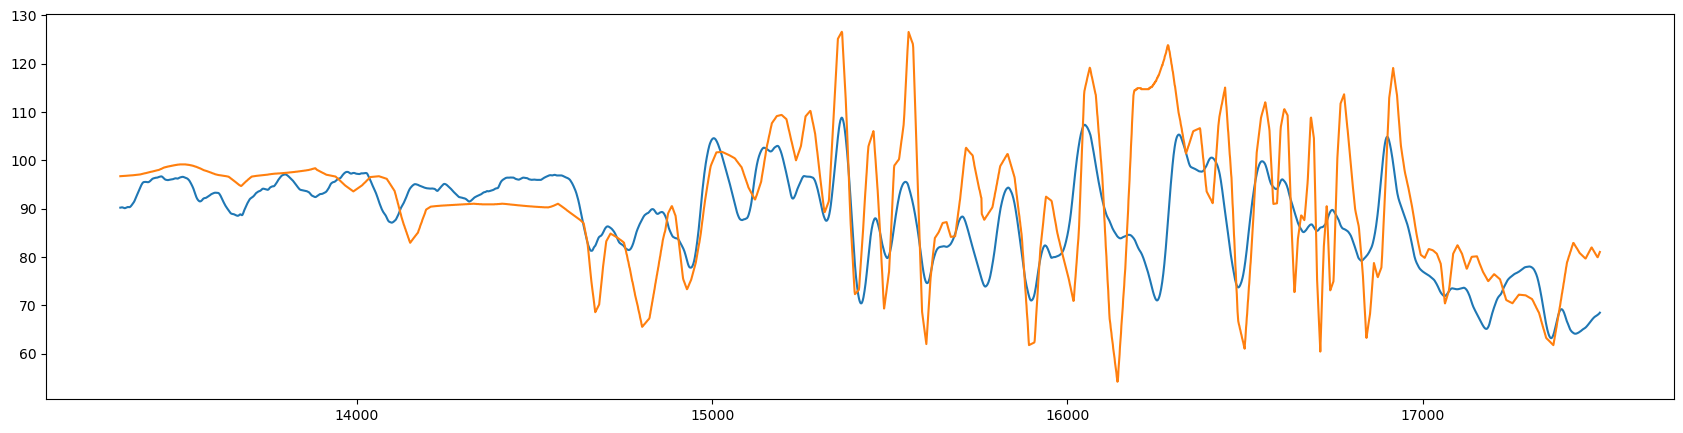

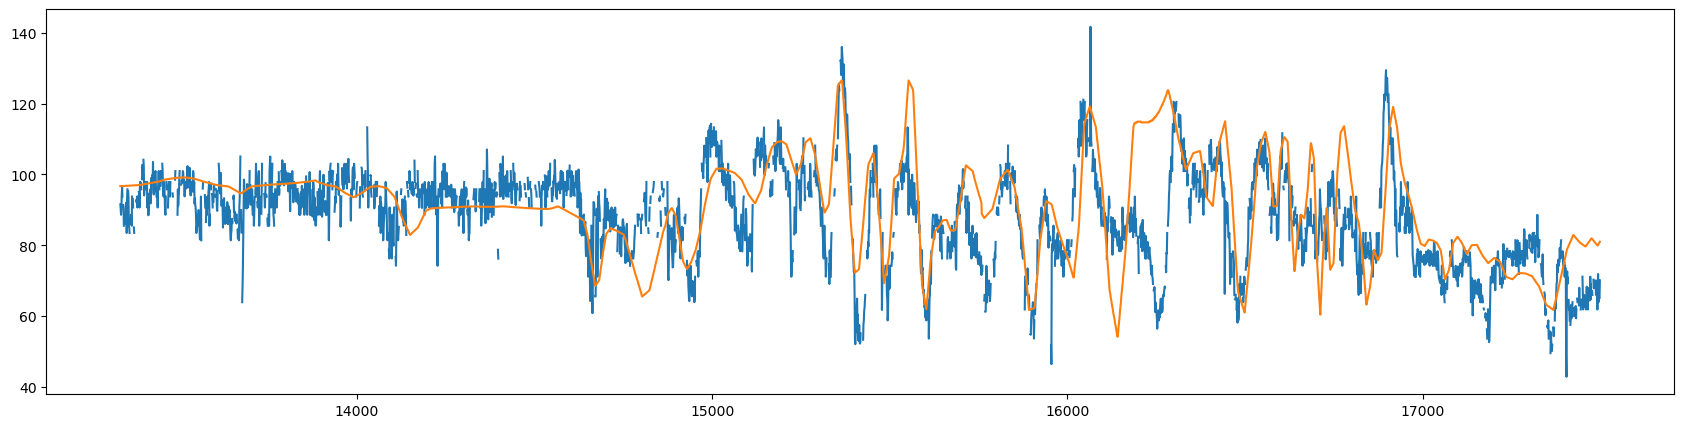

In [131]:
hw = pd.read_csv(train_data + f"/{well}__horizontal_well.csv")
tw = pd.read_csv(train_data + f"/{well}__typewell.csv")
evalz = hw[hw['TVT_input'].isna()]
tvt = evalz['TVT']
md = evalz['MD']

plt.figure(figsize=(21, 5))
plt.plot(md, gr)
plt.plot(md, np.interp(tvt, tw_tvt, tw_gr))

plt.figure(figsize=(21, 5))
plt.plot(md, evalz['GR'])
plt.plot(md, np.interp(tvt, tw['TVT'], tw['GR']))



In [137]:
from sklearn.metrics import root_mean_squared_error as rmse
m = float('inf')
for i, t in enumerate(tvts):
    if rmse(t, tvt) < m:
        m = rmse(t, tvt)
        t_m = t
        print(i)
rmse(t_m, tvt)   

0
3
4
7
8


3.227647229108205

In [145]:
len(tvts)

9

In [163]:
import numpy as np
from scipy.stats import wasserstein_distance
from scipy.spatial.distance import cosine
from fastdtw import fastdtw
import similaritymeasures

import numpy as np
from scipy.stats import pearsonr

def structural_metrics(gr, y):
    """
    Computes scale-invariant and feature-focused metrics to compare signals.
    """
    gr = np.asarray(gr, dtype=float)
    y = np.asarray(y, dtype=float)
    
    # 1. Z-Score Normalization (Removes baseline shift & gain errors)
    z_gr = (gr - np.mean(gr)) / (np.std(gr) + 1e-8)
    z_y = (y - np.mean(y)) / (np.std(y) + 1e-8)
    z_mse = np.mean((z_gr - z_y) ** 2)
    
    # 2. Pearson Correlation Loss (Range 0.0 = perfect match, 2.0 = inverted)
    corr, _ = pearsonr(gr, y)
    pearson_loss = 1.0 - corr
    
    # 3. Second Derivative / Curvature Loss (Focuses on Geological Tops/Peaks)
    d2_gr = np.gradient(np.gradient(gr))
    d2_y = np.gradient(np.gradient(y))
    curvature_loss = np.mean((d2_gr - d2_y) ** 2)
    
    # 4. Normalized Sobolev Loss (Shape + Trend without amplitude bias)
    d1_z_gr = np.gradient(z_gr)
    d1_z_y = np.gradient(z_y)
    z_sobolev = z_mse + np.mean((d1_z_gr - d1_z_y) ** 2)

    return {
        "Z-Normalized MSE": z_mse,
        "Pearson Loss (1 - r)": pearson_loss,
        "Curvature Loss (2nd Deriv)": curvature_loss,
        "Z-Normalized Sobolev": z_sobolev
    }

# Usage:
# results_cand1 = structural_metrics(gr, y_cand1)
# results_cand2 = structural_metrics(gr, y_cand2)


# =====================================================================
# EXAMPLE USAGE WITH YOUR VARIABLES
# =====================================================================
# y = np.interp(tvt, tw['TVT'], tw['GR'])
y = np.interp(tvts[8], tw['TVT'], tw['GR'])
# y = optimal_pred_gr

# gr_ = (gr - gr.mean()) / gr.std()
# y_ = (y - y.mean()) / y.std()

# --- Calculate All Metrics ---
metrics = structural_metrics(gr, y)

# --- Print Summary Table ---
print("\n" + "="*50)
print(f"{'METRIC':<25} | {'VALUE':<15}")
print("="*50)
for name, value in metrics.items():
    print(f"{name:<25} | {value:<15.4f}")
print("="*50)


METRIC                    | VALUE          
Z-Normalized MSE          | 0.3849         
Pearson Loss (1 - r)      | 0.1925         
Curvature Loss (2nd Deriv) | 0.0164         
Z-Normalized Sobolev      | 0.3868         


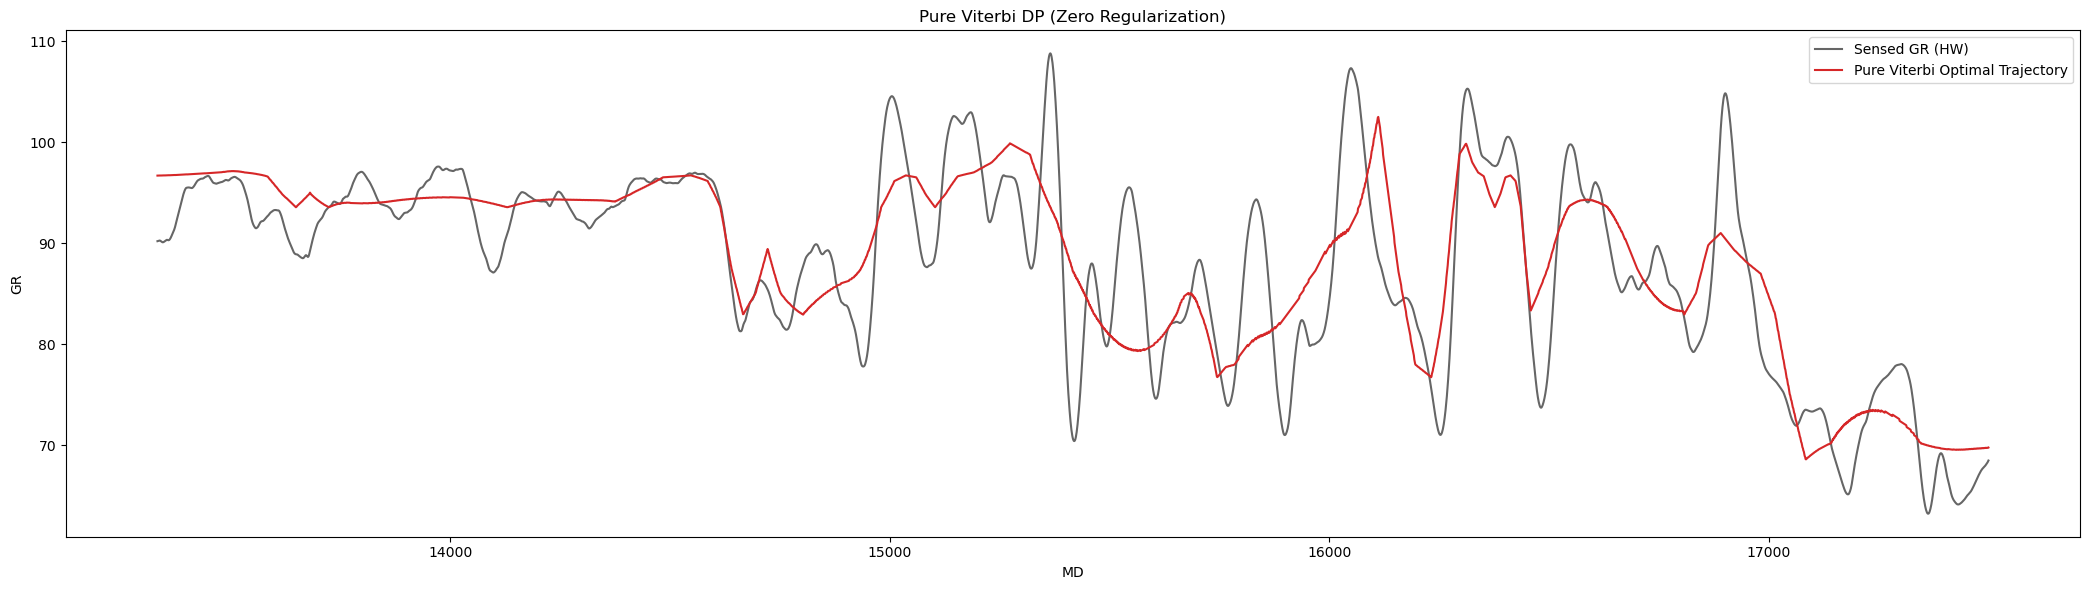

In [115]:

# ==========================================
# 4. RECONSTRUCTION & PLOTTING
# ==========================================
optimal_pred_gr = np.zeros(len(evalz))
optimal_pred_tvt = np.zeros(len(evalz))
optimal_pred_m = np.zeros(len(evalz))
optimal_pred_z_tvt = np.zeros(len(evalz))
# tw_gr_raw = tw['GR'].values # Using un-standardized GR for final plotting
tw_gr_raw = tw_gr

for i in range(num_chunks):
    start_idx = boundaries[i]
    end_idx = boundaries[i+1]
    chunk_len = end_idx - start_idx
    steps = np.arange(chunk_len)
    
    hypo_z_tvt = optimal_anchors[i] + (optimal_m[i] * steps)
    hypo_tvt = hypo_z_tvt + z[start_idx:end_idx] + tvt0
    
    optimal_pred_gr[start_idx:end_idx] = np.interp(hypo_tvt, tw_tvt, tw_gr_raw)
    optimal_pred_tvt[start_idx:end_idx] = hypo_tvt
    optimal_pred_m[start_idx:end_idx] = optimal_m[i]
    optimal_pred_z_tvt[start_idx:end_idx] = hypo_z_tvt

plt.figure(figsize=(21, 6))
# plt.plot(evalz['MD'], evalz['GR'], label='Sensed GR (HW)', color='black', alpha=0.6)
plt.plot(evalz['MD'], gr, label='Sensed GR (HW)', color='black', alpha=0.6)
plt.plot(evalz['MD'], optimal_pred_gr, label='Pure Viterbi Optimal Trajectory', color='tab:red', linewidth=1.5)
# plt.plot(evalz['MD'], np.interp(evalz['TVT'], tw['TVT'], tw_gr), label='orig', linewidth=1.5)
# for pos in evalz['MD'].iloc[peaks]:
#     plt.axvline(x=pos, color='blue', linestyle='--', alpha=0.4)
plt.title('Pure Viterbi DP (Zero Regularization)')
plt.xlabel('MD')
plt.ylabel('GR')
plt.legend()
plt.tight_layout()
plt.show()

Searching top 300 nodes for 25 distinct paths...
Found 9 distinct paths meeting the separation criteria.


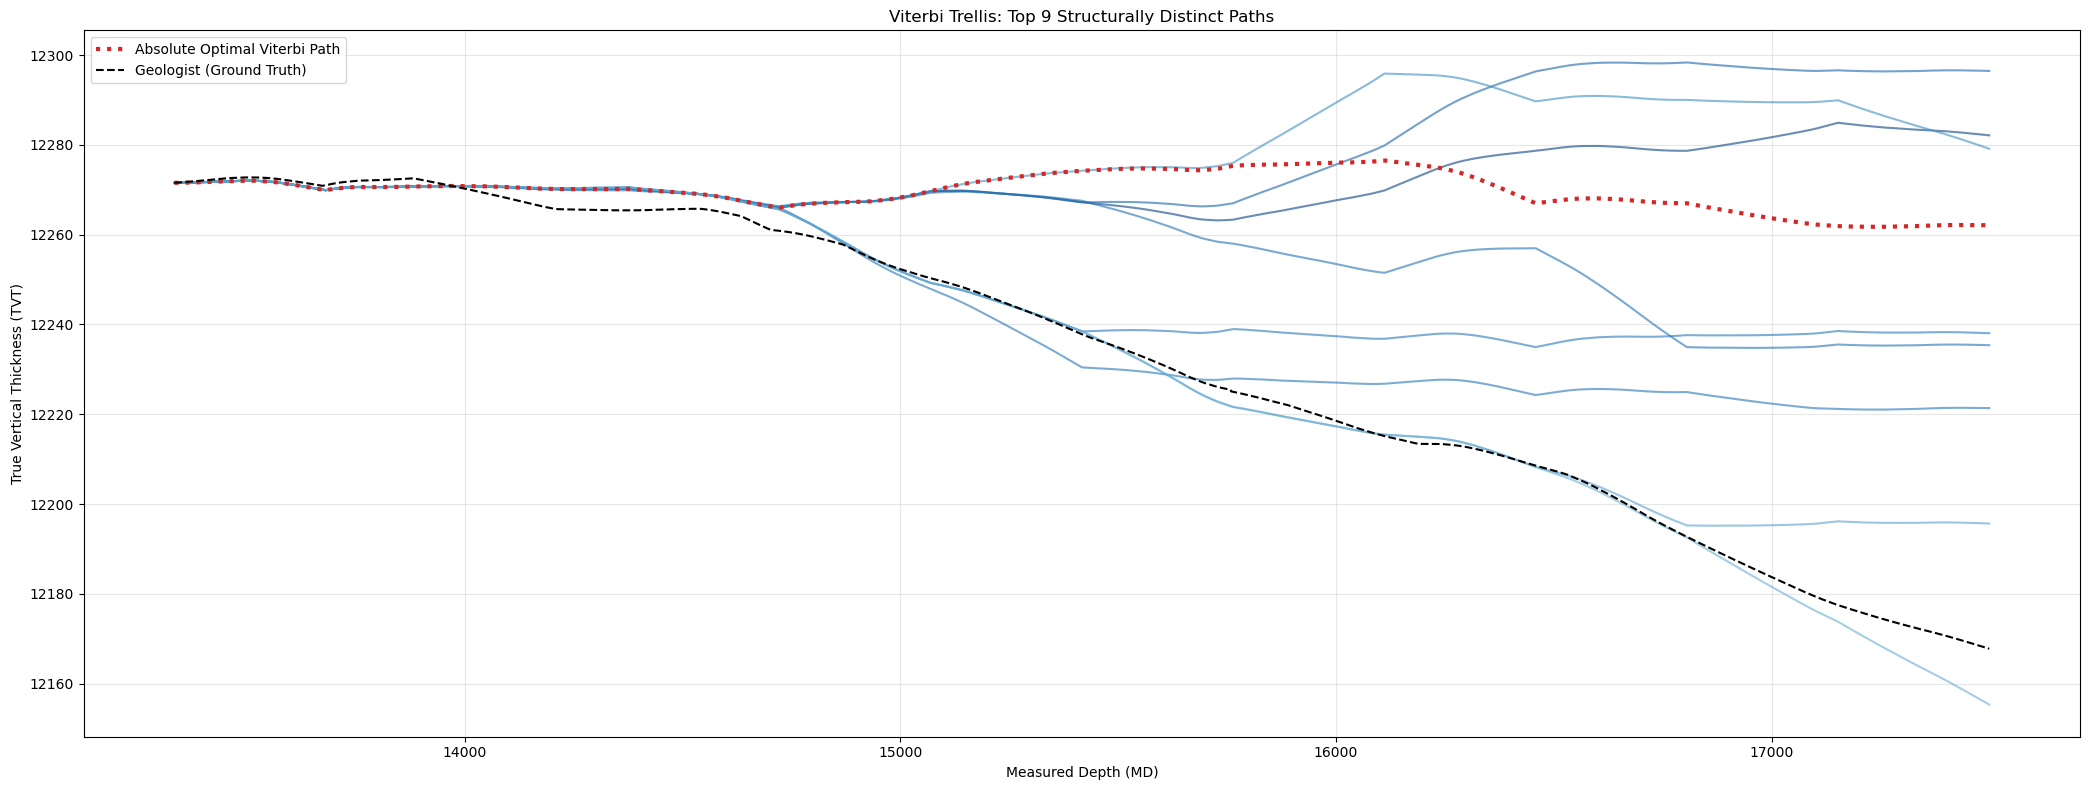

In [121]:
import matplotlib.cm as cm

# ==========================================
# 1. SETUP & FINDING CANDIDATE PATHS
# ==========================================
valid_final_nodes = np.where(costs[-1] != np.inf)[0]
sorted_final_nodes = valid_final_nodes[np.argsort(costs[-1][valid_final_nodes])]

# PARAMETERS TO TUNE
x_paths_to_show = 25          # How many distinct trajectories you want to plot
min_separation_tvt = 5.0     # Minimum average TVT distance required between paths
pool_size = min(300, len(sorted_final_nodes)) # How deep to search for alternatives
tvts = list()

print(f"Searching top {pool_size} nodes for {x_paths_to_show} distinct paths...")

# ==========================================
# 2. EXTRACT SKELETONS & APPLY SPATIAL FILTER
# ==========================================
candidate_trajectories = []

# Step A: Fast backtrace just to get the anchor positions (the skeleton)
for node in sorted_final_nodes[:pool_size]:
    temp_anchors = np.zeros(num_chunks + 1)
    curr_k = node
    temp_anchors[-1] = anchors[-1][curr_k]
    
    for i in range(num_chunks - 1, -1, -1):
        curr_k = backpointer[i+1][curr_k]
        temp_anchors[i] = anchors[i][curr_k]
        
    candidate_trajectories.append((node, temp_anchors))

# Step B: Greedily select paths that are structurally distinct
selected_paths = []
selected_anchors = []

for node, traj in candidate_trajectories:
    if not selected_paths:
        # Always keep the absolute best path
        selected_paths.append(node)
        selected_anchors.append(traj)
        continue
        
    # Check physical distance against ALL already selected paths
    is_distinct = True
    for sel_traj in selected_anchors:
        # Mean Absolute Error (MAE) of the anchors
        # Paths that only diverge at the end will have a tiny MAE.
        # Paths that diverge early will have a large MAE.
        mae = np.mean(np.abs(traj - sel_traj))
        
        if mae < min_separation_tvt:
            is_distinct = False
            break # Too similar to an existing path, throw it out
            
    if is_distinct:
        selected_paths.append(node)
        selected_anchors.append(traj)
        
    if len(selected_paths) == x_paths_to_show:
        break

print(f"Found {len(selected_paths)} distinct paths meeting the separation criteria.")

# ==========================================
# 3. RECONSTRUCT TVT AND PLOT
# ==========================================
# Extract the costs for the color map based ONLY on the selected paths
top_costs = costs[-1][selected_paths]
min_cost = np.min(top_costs)
max_cost = np.max(top_costs)

plt.figure(figsize=(21, 8))

for rank, (start_node, temp_anchors) in enumerate(zip(selected_paths, selected_anchors)):
    
    # We already have the anchors, so we just need to reconstruct the slopes and TVT
    temp_m = np.zeros(num_chunks)
    for i in range(num_chunks):
        chunk_len = boundaries[i+1] - boundaries[i]
        temp_m[i] = (temp_anchors[i+1] - temp_anchors[i]) / chunk_len
        
    temp_pred_tvt = np.zeros(len(evalz))
    for i in range(num_chunks):
        start_idx = boundaries[i]
        end_idx = boundaries[i+1]
        chunk_len = end_idx - start_idx
        steps = np.arange(chunk_len)
        
        hypo_z_tvt = temp_anchors[i] + (temp_m[i] * steps)
        temp_pred_tvt[start_idx:end_idx] = hypo_z_tvt + z[start_idx:end_idx] + tvt0
        
    # Plotting logic
    if rank == 0:
        # Absolute best path gets bold red
        best_pred_tvt = temp_pred_tvt.copy()
        plt.plot(evalz['MD'], best_pred_tvt, color='tab:red', linestyle=':', linewidth=3.0, label='Absolute Optimal Viterbi Path', zorder=10)
        tvts.append(best_pred_tvt)
    else:
        # Alternate minima get heatmapped
        normalized_cost = (costs[-1][start_node] - min_cost) / ((max_cost - min_cost) + 1e-8)
        color = cm.Blues(1.0 - (normalized_cost * 0.5)) 
        plt.plot(evalz['MD'], temp_pred_tvt, color=color, alpha=0.6, linewidth=1.5, zorder=5)
        tvts.append(temp_pred_tvt)

# Plot Geologist Ground Truth in Dashed Black
plt.plot(evalz['MD'], evalz['TVT'], color='black', linestyle='--', linewidth=1.5, label='Geologist (Ground Truth)', zorder=15)

plt.title(f'Viterbi Trellis: Top {len(selected_paths)} Structurally Distinct Paths')
plt.xlabel('Measured Depth (MD)')
plt.ylabel('True Vertical Thickness (TVT)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Searching top 300 nodes for 9 distinct paths...
Found 7 distinct paths meeting the separation criteria.


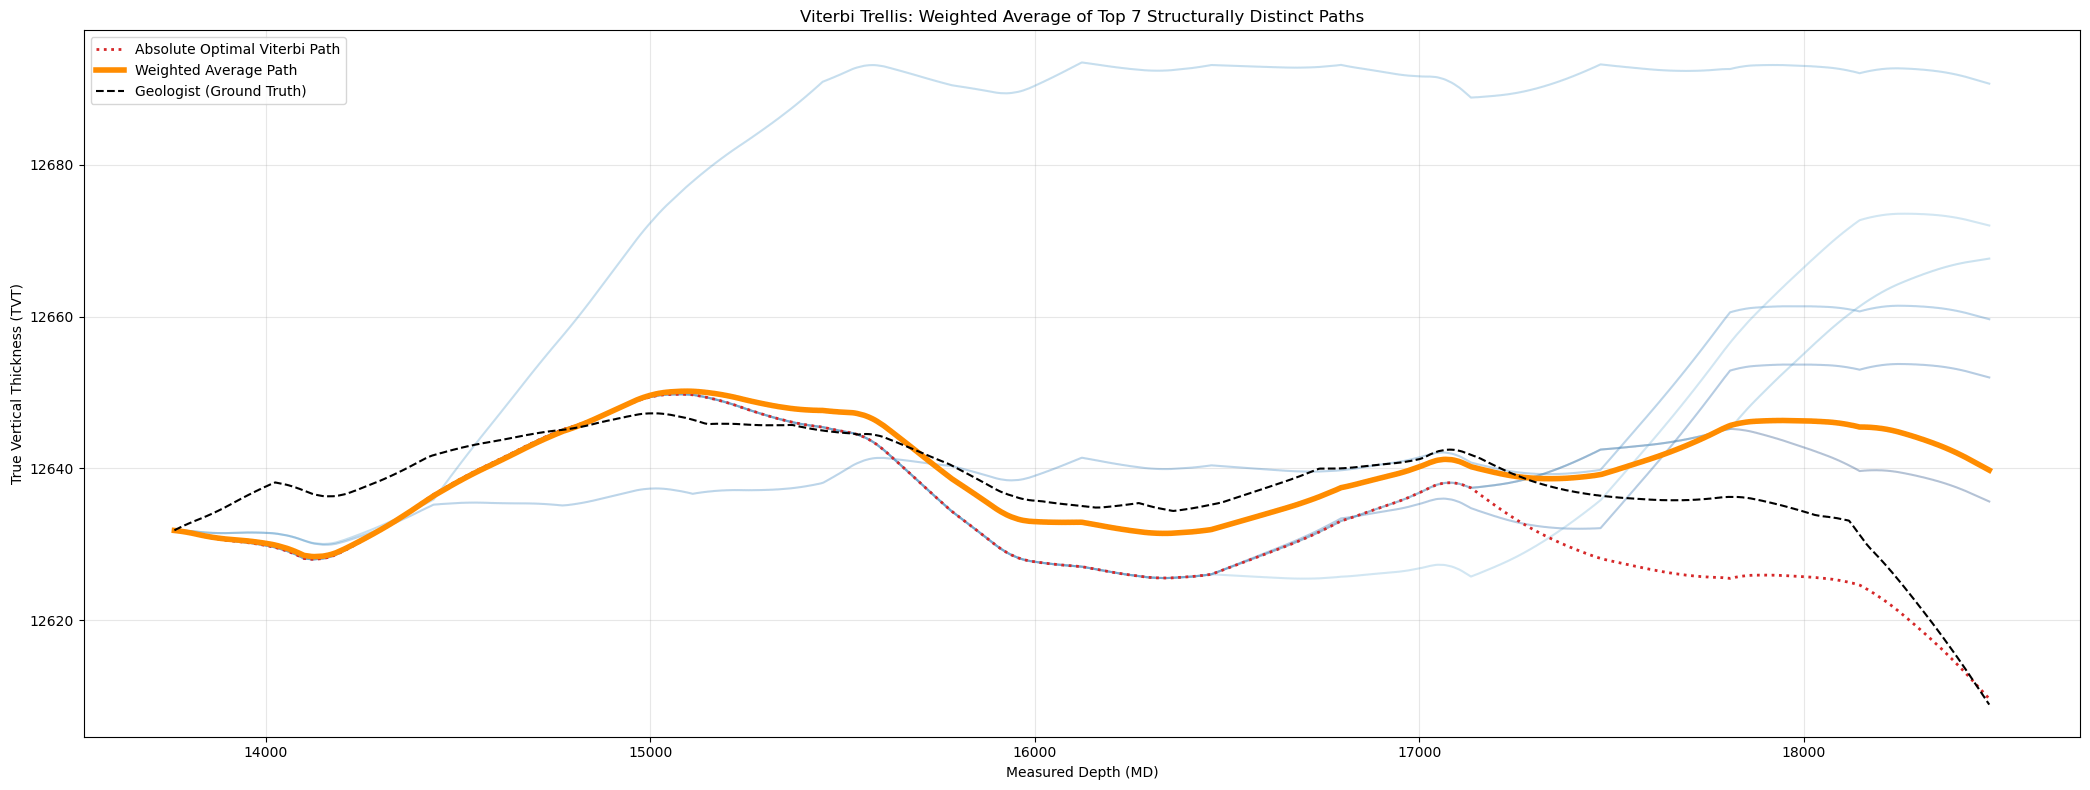

In [91]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm

# ==========================================
# 1. SETUP & FINDING CANDIDATE PATHS
# ==========================================
valid_final_nodes = np.where(costs[-1] != np.inf)[0]
sorted_final_nodes = valid_final_nodes[np.argsort(costs[-1][valid_final_nodes])]

# PARAMETERS TO TUNE
x_paths_to_show = 9          # How many distinct trajectories you want to plot
min_separation_tvt = 3.0     # Minimum average TVT distance required between paths
pool_size = min(300, len(sorted_final_nodes)) # How deep to search for alternatives

print(f"Searching top {pool_size} nodes for {x_paths_to_show} distinct paths...")

# ==========================================
# 2. EXTRACT SKELETONS & APPLY SPATIAL FILTER
# ==========================================
candidate_trajectories = []

# Step A: Fast backtrace just to get the anchor positions (the skeleton)
for node in sorted_final_nodes[:pool_size]:
    temp_anchors = np.zeros(num_chunks + 1)
    curr_k = node
    temp_anchors[-1] = anchors[-1][curr_k]
    
    for i in range(num_chunks - 1, -1, -1):
        curr_k = backpointer[i+1][curr_k]
        temp_anchors[i] = anchors[i][curr_k]
        
    candidate_trajectories.append((node, temp_anchors))

# Step B: Greedily select paths that are structurally distinct
selected_paths = []
selected_anchors = []

for node, traj in candidate_trajectories:
    if not selected_paths:
        # Always keep the absolute best path
        selected_paths.append(node)
        selected_anchors.append(traj)
        continue
        
    # Check physical distance against ALL already selected paths
    is_distinct = True
    for sel_traj in selected_anchors:
        # Mean Absolute Error (MAE) of the anchors
        mae = np.mean(np.abs(traj - sel_traj))
        
        if mae < min_separation_tvt:
            is_distinct = False
            break # Too similar to an existing path, throw it out
            
    if is_distinct:
        selected_paths.append(node)
        selected_anchors.append(traj)
        
    if len(selected_paths) == x_paths_to_show:
        break

print(f"Found {len(selected_paths)} distinct paths meeting the separation criteria.")

# ==========================================
# 3. RECONSTRUCT TVT, CALCULATE WEIGHTED AVG, AND PLOT
# ==========================================
# Extract the costs for the color map based ONLY on the selected paths
top_costs = costs[-1][selected_paths]
min_cost = np.min(top_costs)
max_cost = np.max(top_costs)

norm_costs = (top_costs - min_cost) / (max_cost - min_cost + 1e-8)
alpha = 2.0 
weights = np.exp(-alpha * norm_costs)
weights = weights / np.sum(weights)

# Calculate weights based on Inverse Cost
# We subtract min_cost and add 1e-5 to highly weight the absolute best path
# weights = 1.0 / ((top_costs - min_cost) + 1e-5)
# weights = weights / np.sum(weights) # Normalize so weights sum to 1.0

# Store all fully reconstructed paths here to average them later
all_pred_tvts = []

plt.figure(figsize=(21, 8))

for rank, (start_node, temp_anchors) in enumerate(zip(selected_paths, selected_anchors)):
    
    # Reconstruct the slopes and TVT
    temp_m = np.zeros(num_chunks)
    for i in range(num_chunks):
        chunk_len = boundaries[i+1] - boundaries[i]
        temp_m[i] = (temp_anchors[i+1] - temp_anchors[i]) / chunk_len
        
    temp_pred_tvt = np.zeros(len(evalz))
    for i in range(num_chunks):
        start_idx = boundaries[i]
        end_idx = boundaries[i+1]
        chunk_len = end_idx - start_idx
        steps = np.arange(chunk_len)
        
        hypo_z_tvt = temp_anchors[i] + (temp_m[i] * steps)
        temp_pred_tvt[start_idx:end_idx] = hypo_z_tvt + z[start_idx:end_idx] + tvt0
        
    # Save to our collection
    all_pred_tvts.append(temp_pred_tvt)
    
    # Plotting logic for individual paths
    if rank == 0:
        # Absolute best path gets a dotted red line
        plt.plot(evalz['MD'], temp_pred_tvt, color='tab:red', linestyle=':', linewidth=2.0, label='Absolute Optimal Viterbi Path', zorder=10)
    else:
        # Alternate minima get heatmapped
        normalized_cost = (costs[-1][start_node] - min_cost) / ((max_cost - min_cost) + 1e-8)
        color = cm.Blues(1.0 - (normalized_cost * 0.5)) 
        # Made these slightly more transparent so the average path pops out
        plt.plot(evalz['MD'], temp_pred_tvt, color=color, alpha=0.3, linewidth=1.5, zorder=5)

# ----------------------------------------------------
# COMPUTE AND PLOT THE WEIGHTED AVERAGE PATH
# ----------------------------------------------------
all_pred_tvts = np.array(all_pred_tvts)
weighted_avg_tvt = np.average(all_pred_tvts, axis=0, weights=weights)

plt.plot(evalz['MD'], weighted_avg_tvt, color='darkorange', linestyle='-', linewidth=4.0, label='Weighted Average Path', zorder=12)

# Plot Geologist Ground Truth in Dashed Black
plt.plot(evalz['MD'], evalz['TVT'], color='black', linestyle='--', linewidth=1.5, label='Geologist (Ground Truth)', zorder=15)

plt.title(f'Viterbi Trellis: Weighted Average of Top {len(selected_paths)} Structurally Distinct Paths')
plt.xlabel('Measured Depth (MD)')
plt.ylabel('True Vertical Thickness (TVT)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [55]:
print(weights)

[0.34915094 0.25147004 0.17715091 0.06603681 0.05977778 0.04916108
 0.04725244]


In [56]:
np.sqrt(np.mean((optimal_pred_tvt[:] - tvt)**2))

np.float64(67.67885381116544)

In [57]:
erros = list()
for tvt_pred in all_pred_tvts:
    erros.append(np.sqrt(np.mean((tvt_pred - tvt)**2)))
min(erros)

np.float64(6.135657896565599)

In [58]:

np.sqrt(np.mean((weighted_avg_tvt[:] - tvt)**2))

np.float64(50.76465233713955)

np.float64(12177.94)

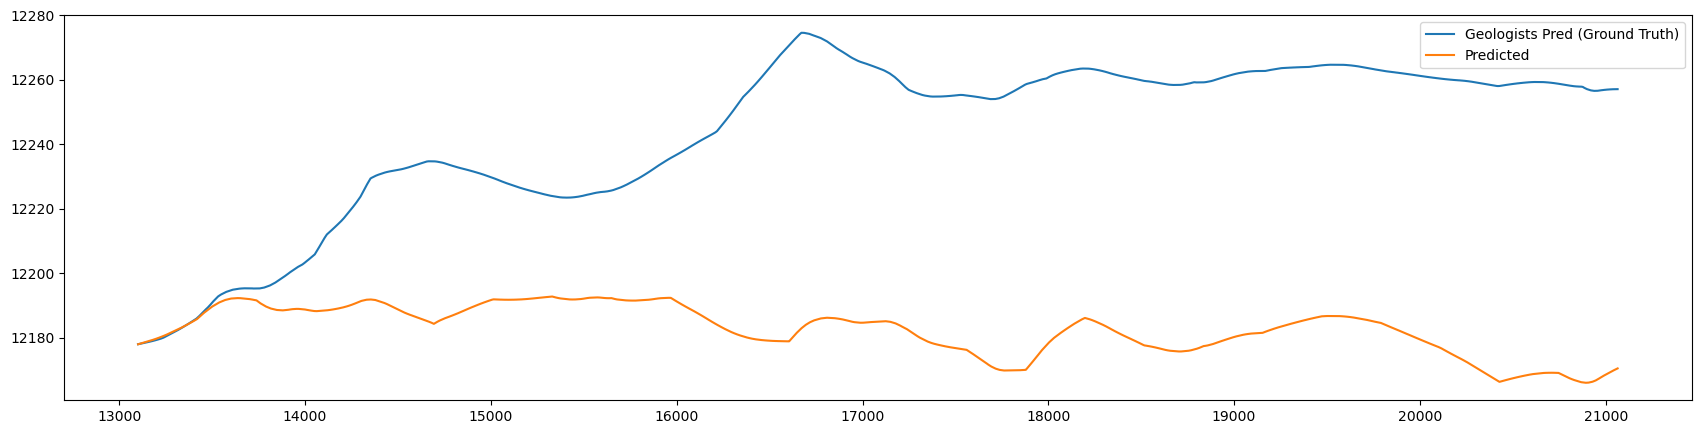

In [59]:
plt.figure(figsize=(21, 5))
plt.plot(evalz['MD'], evalz['TVT'], label='Geologists Pred (Ground Truth)')
plt.plot(evalz['MD'], optimal_pred_tvt, label='Predicted')
plt.legend()
tvt0

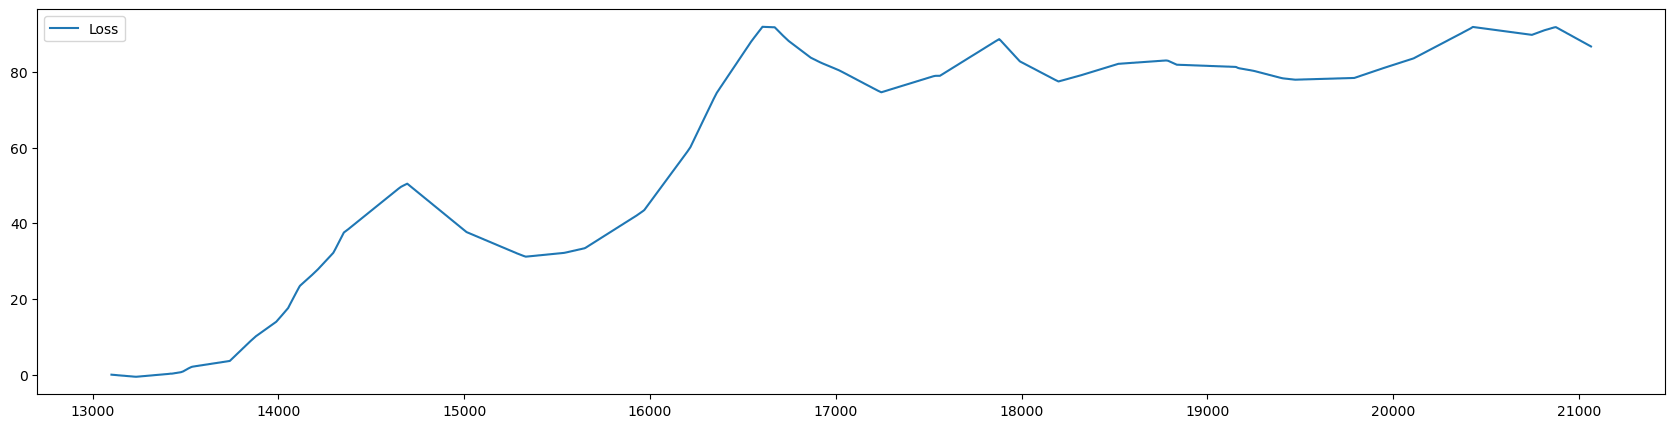

In [60]:
plt.figure(figsize=(21, 5))
plt.plot(evalz['MD'], evalz['TVT'] - optimal_pred_tvt, label='Loss')
plt.legend()

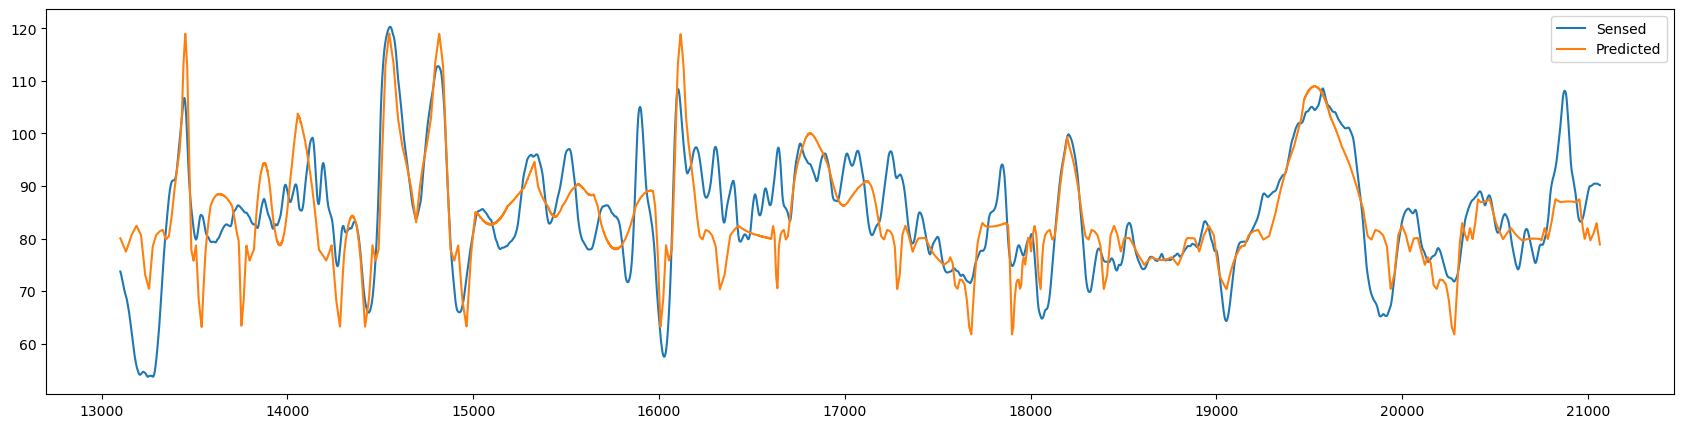

In [61]:
plt.figure(figsize=(21, 5))
plt.plot(evalz['MD'], gr, label='Sensed')
plt.plot(evalz['MD'], optimal_pred_gr, label='Predicted')
# plt.plot(evalz['MD'], np.interp(evalz['TVT'], tw_tvt, tw_gr), label='Geologist (Ground Truth)')
plt.legend()

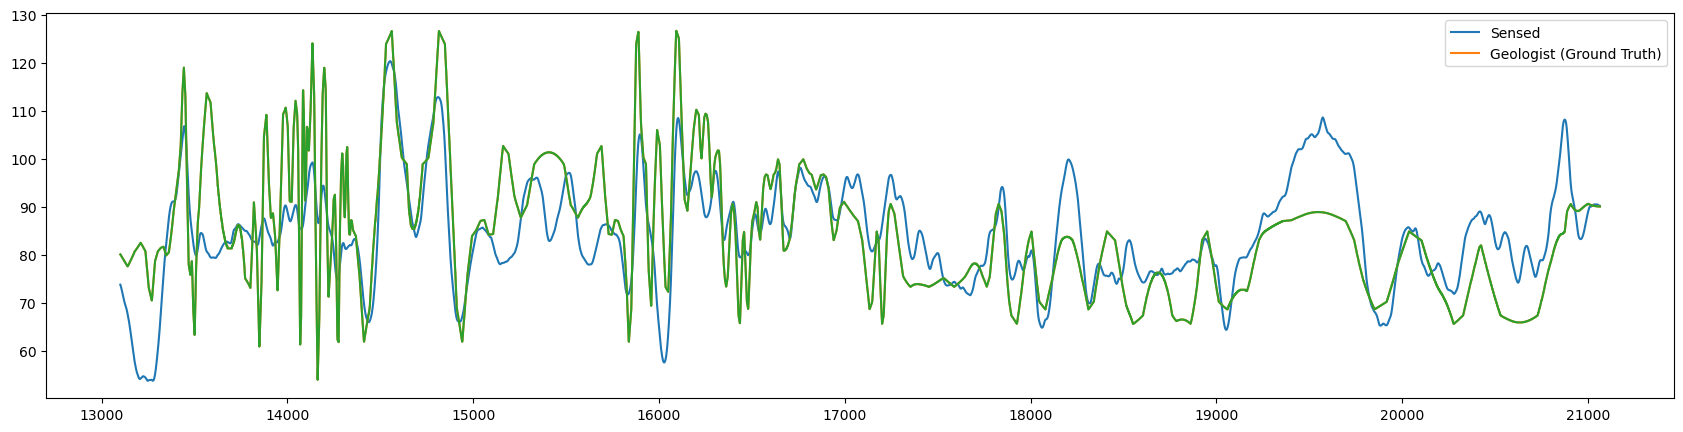

In [62]:
plt.figure(figsize=(21, 5))
plt.plot(evalz['MD'], remove_rotation_noise(evalz['GR']), label='Sensed')
# # plt.plot(evalz['MD'], optimal_pred_gr, label='Predicted')
plt.plot(evalz['MD'], np.interp(evalz['TVT'], tw_tvt, tw_gr), label='Geologist (Ground Truth)')
plt.legend()
plt.plot(evalz['MD'], np.interp(evalz['TVT'], tw['TVT'], tw['GR']), label='Geologist (Ground Truth): Orig')

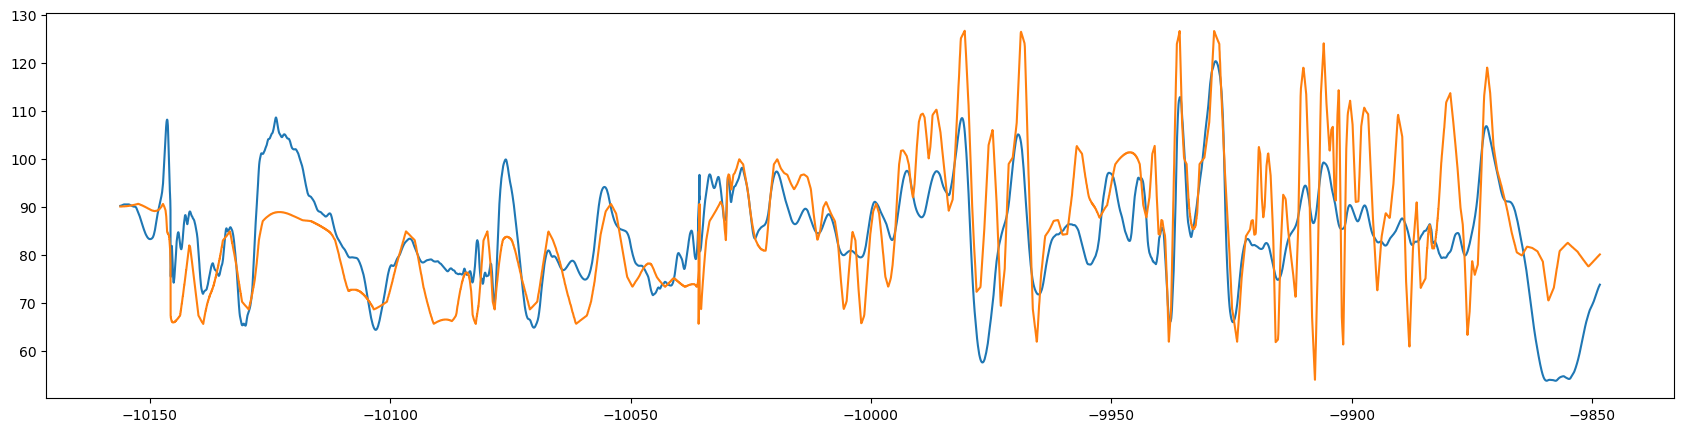

In [63]:
plt.figure(figsize=(21, 5))
plt.plot(evalz['Z'], gr)
# plt.plot(evalz['Z'], optimal_pred_gr)
plt.plot(evalz['Z'], np.interp(evalz['TVT'], tw_tvt, tw_gr))

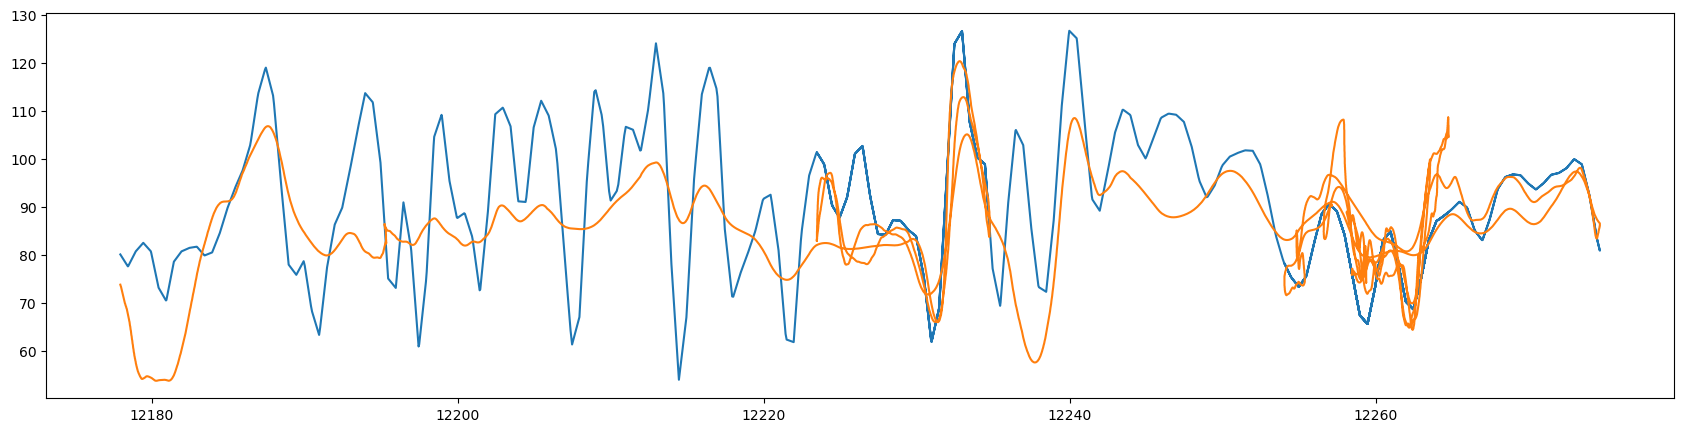

In [64]:
plt.figure(figsize=(21, 5))
# plt.plot(optimal_pred_tvt, optimal_pred_gr, label='Pred')
plt.plot(evalz['TVT'], np.interp(evalz['TVT'], tw_tvt, tw_gr), label='Geo Pred (Ground Truth)')
plt.plot(evalz['TVT'], gr, label='sensed')

In [65]:
m_z, c_z = np.polyfit(evalz['MD'], evalz['Z'], deg=1)
evalz['pred_Z'] = evalz['Z'] - m_z * evalz['MD'] - c_z
evalz['Z+TVT'] = evalz['pred_Z'] + evalz['TVT'] - evalz['TVT'].iloc[0]

np.float64(-0.038904968221295765)

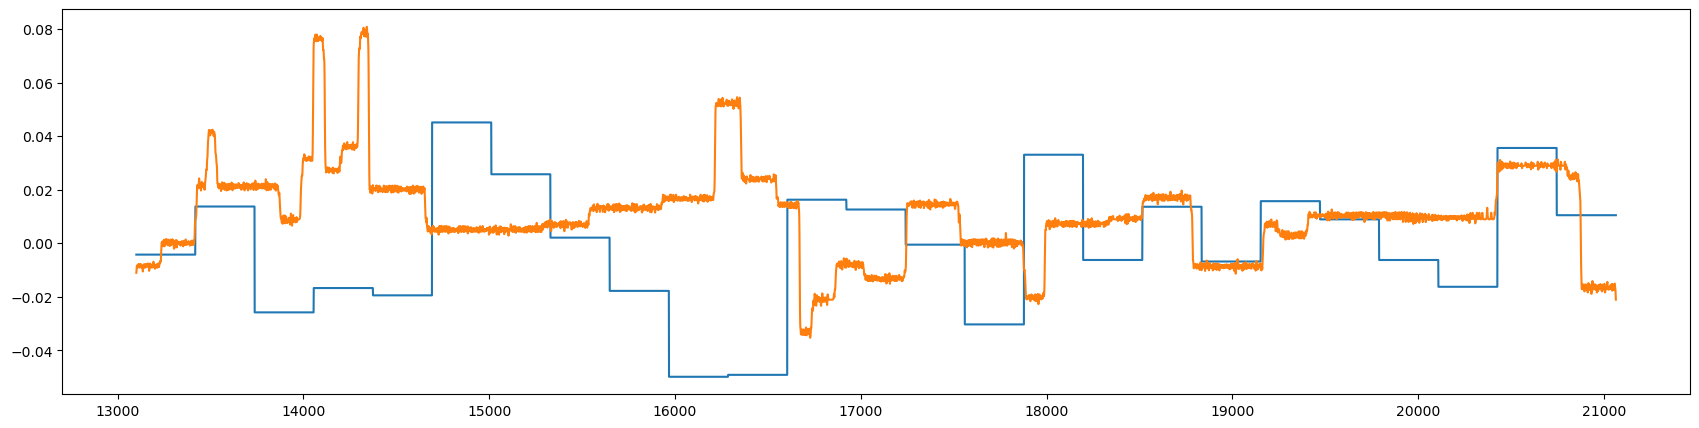

In [66]:
plt.figure(figsize=(21, 5))
plt.plot(evalz['MD'], optimal_pred_m)
plt.plot(evalz['MD'], remove_rotation_noise(evalz['Z+TVT'].diff().clip(upper=0.1, lower=-0.1), cutoff=0.1))
m_z

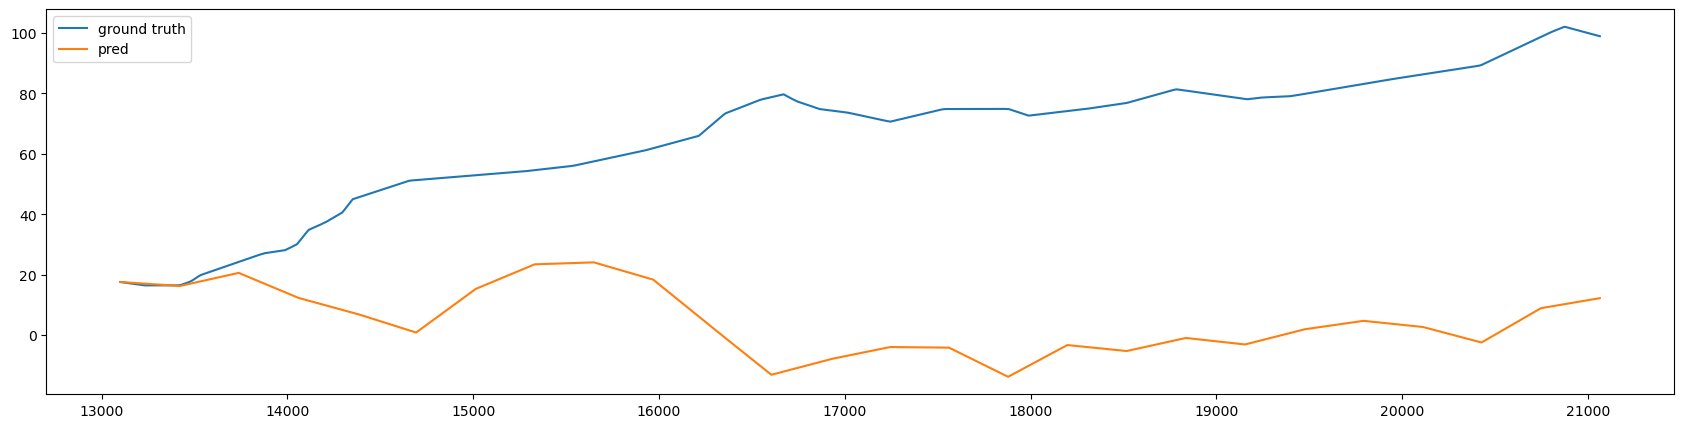

In [67]:
plt.figure(figsize=(21, 5))
plt.plot(evalz['MD'], evalz['Z+TVT'], label='ground truth')
plt.plot(evalz['MD'], optimal_pred_z_tvt, label='pred')
plt.legend()

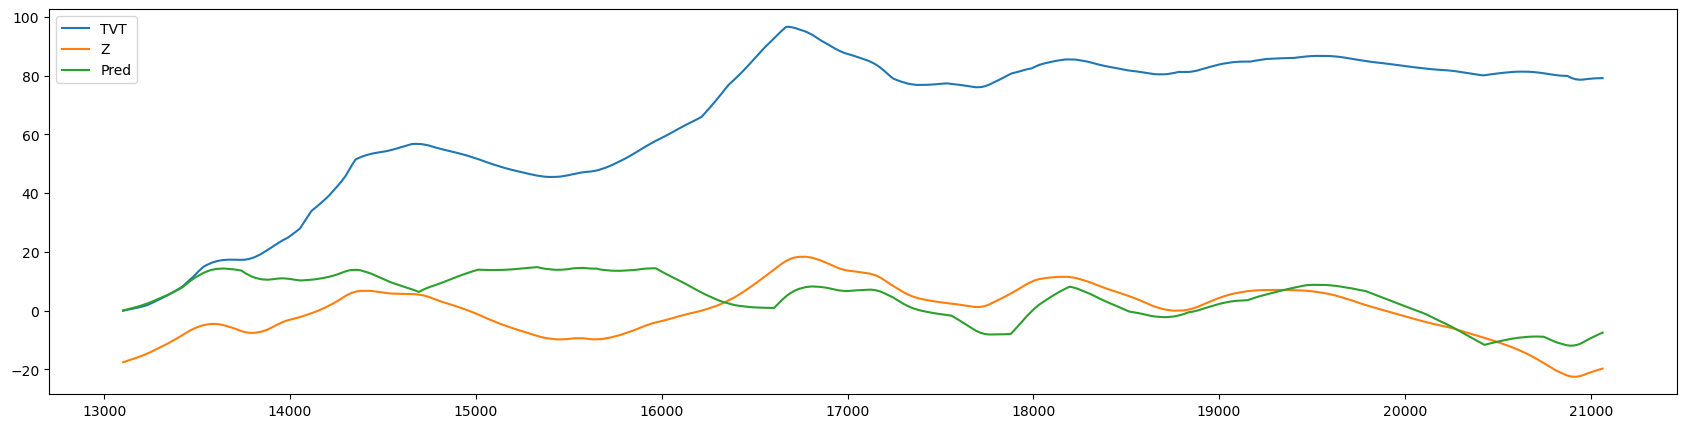

In [68]:
plt.figure(figsize=(21, 5))
plt.plot(evalz['MD'], evalz['TVT'] - evalz['TVT'].iloc[0], label='TVT')
plt.plot(evalz['MD'], -evalz['pred_Z'], label='Z')
plt.plot(evalz['MD'], optimal_pred_tvt - optimal_pred_tvt[0], label='Pred')
plt.legend()

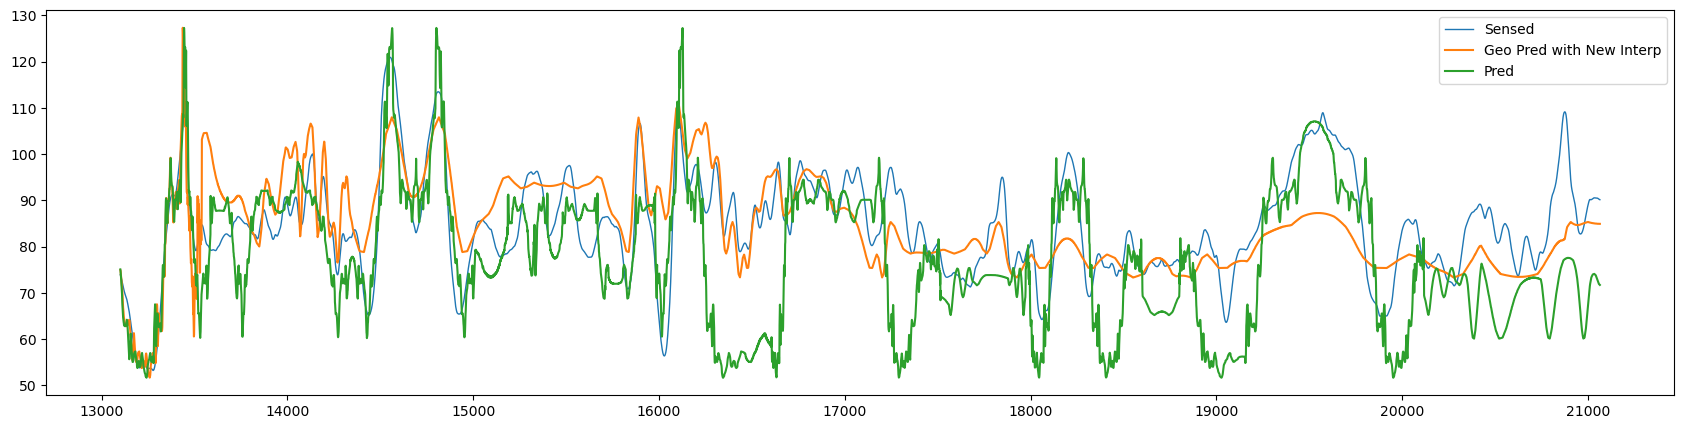

In [69]:
plt.figure(figsize=(21, 5))
mask = hw['TVT_input'].isna()
given = hw[~mask][['TVT', 'GR']]
given['GR'] = (given['GR'])
max_tvt = given['TVT'].max()
tw_filtered = tw[tw['TVT'] > max_tvt]

merged_df = pd.concat([given, tw_filtered]).sort_values(by='TVT')

plt.plot(evalz['MD'], (remove_rotation_noise(evalz['GR'], cutoff=0.01)), linewidth=1, label='Sensed')
plt.plot(evalz['MD'], np.interp(evalz['TVT'], merged_df['TVT'], remove_rotation_noise(merged_df['GR'], cutoff=0.1)), label='Geo Pred with New Interp')
# plt.xlim(14500, 16500)
plt.plot(evalz['MD'], np.interp(optimal_pred_tvt, merged_df['TVT'], remove_rotation_noise(merged_df['GR'], cutoff=0.1)), label='Pred')
plt.legend()

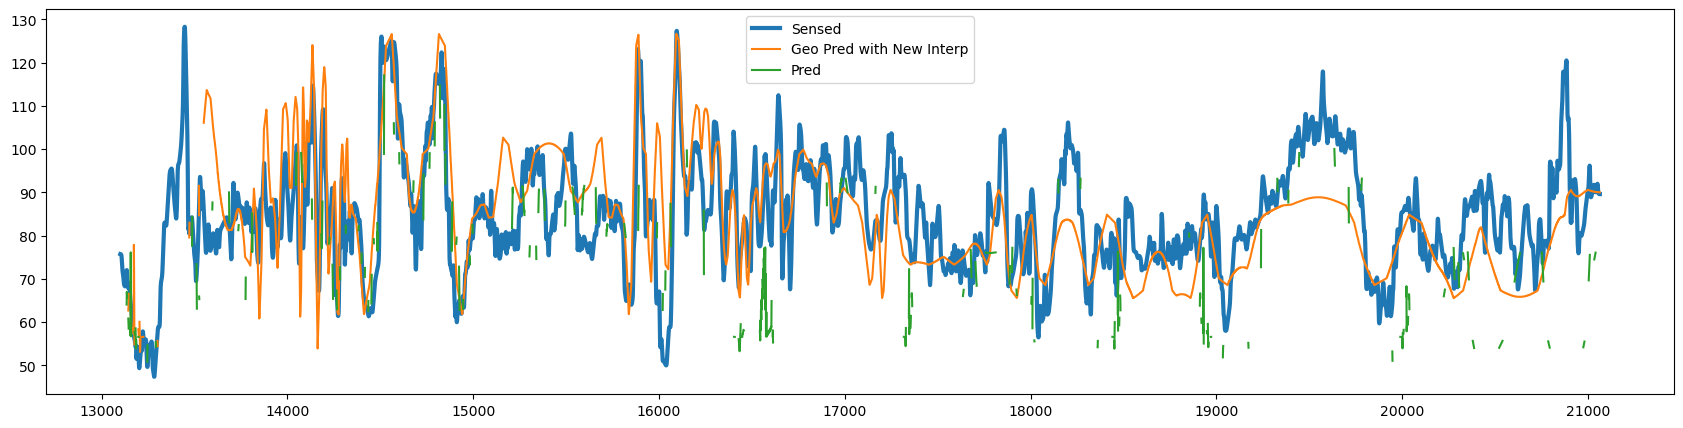

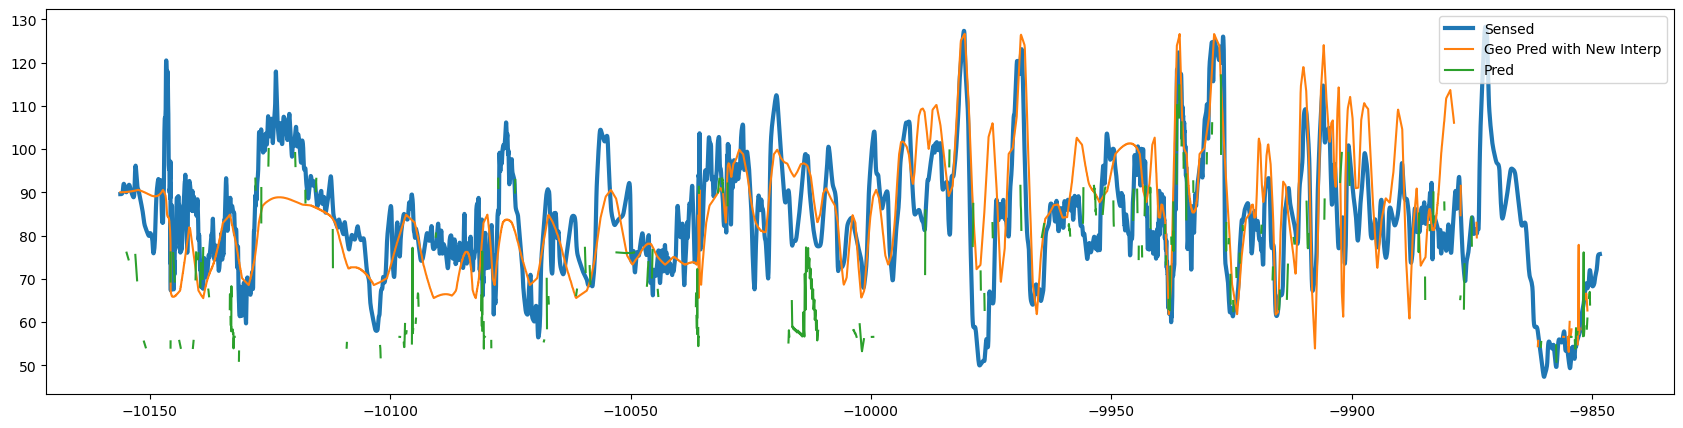

In [70]:
plt.figure(figsize=(21, 5))
mask = hw['TVT_input'].isna()
given = hw[~mask][['TVT', 'GR']]
given['GR'] = (given['GR'])
max_tvt = given['TVT'].max()
tw_filtered = tw[tw['TVT'] > max_tvt]

merged_df = pd.concat([given, tw_filtered]).sort_values(by='TVT')

plt.plot(evalz['MD'], (remove_rotation_noise(evalz['GR'], cutoff=0.1)), linewidth=3, label='Sensed')
plt.plot(evalz['MD'], np.interp(evalz['TVT'], merged_df['TVT'], (merged_df['GR'])), label='Geo Pred with New Interp')
# plt.xlim(14500, 16500)
plt.plot(evalz['MD'], np.interp(optimal_pred_tvt, merged_df['TVT'], (merged_df['GR'])), label='Pred')
plt.legend()


plt.figure(figsize=(21, 5))
plt.plot(evalz['Z'], (remove_rotation_noise(evalz['GR'], cutoff=0.1)), linewidth=3, label='Sensed')
plt.plot(evalz['Z'], np.interp(evalz['TVT'], merged_df['TVT'], (merged_df['GR'])), label='Geo Pred with New Interp')
plt.plot(evalz['Z'], np.interp(optimal_pred_tvt, merged_df['TVT'], (merged_df['GR'])), label='Pred')
plt.legend()

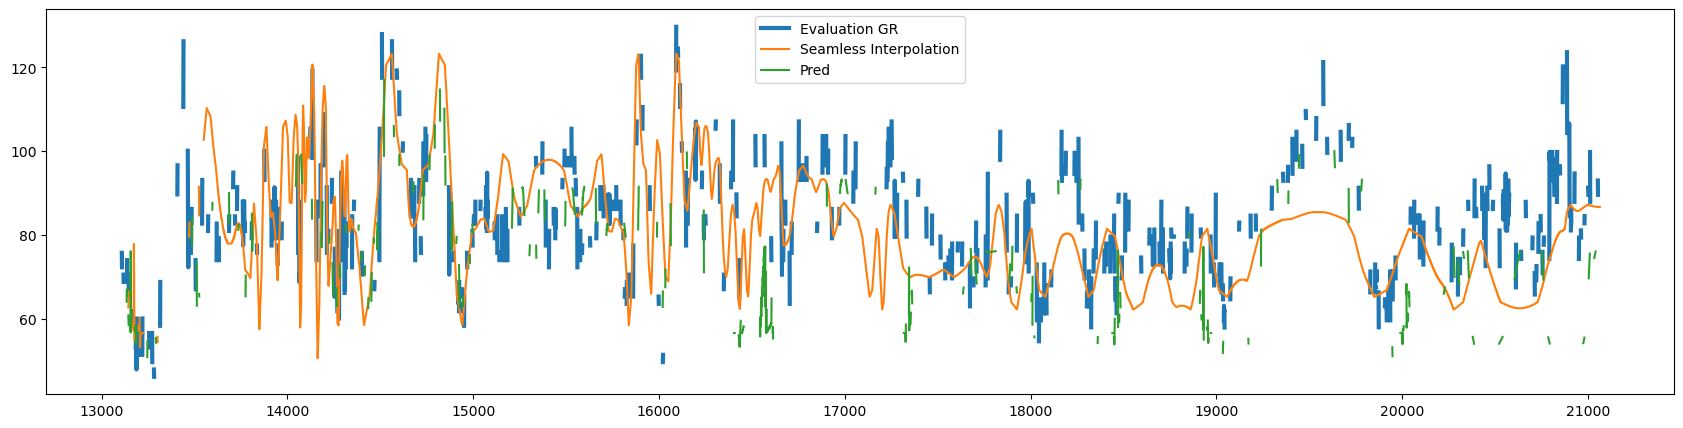

In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

mask = hw['TVT_input'].isna()
given = hw[~mask][['TVT', 'GR']].copy()
# given['GR'] = remove_rotation_noise(given['GR'], cutoff=0.3)
given['GR'] = (given['GR'])

max_tvt = given['TVT'].max()

# 1. Define an overlap window at the boundary (e.g., the last 30 feet of known data)
window_size = 30.0
overlap_start = max_tvt - window_size

# 2. Calculate the baseline average for BOTH logs inside this exact same window
given_mean = given[given['TVT'] >= overlap_start]['GR'].mean()
tw_overlap_mean = tw[(tw['TVT'] >= overlap_start) & (tw['TVT'] <= max_tvt)]['GR'].mean()

# 3. Calculate the shift required to force the Typewell to match the actual well's baseline
shift_value = given_mean - tw_overlap_mean

# 4. Filter the Typewell and apply the DC Shift
tw_filtered = tw[tw['TVT'] > max_tvt].copy()
tw_filtered['GR'] = tw_filtered['GR'] + shift_value

# 5. Concatenate for a seamless fusion
merged_df = pd.concat([given, tw_filtered]).sort_values(by='TVT')

# Plotting the results
plt.figure(figsize=(21, 5))
plt.plot(evalz['MD'], (evalz['GR']), linewidth=3, label="Evaluation GR")
plt.plot(evalz['MD'], np.interp(evalz['TVT'], merged_df['TVT'], merged_df['GR']), label="Seamless Interpolation")
plt.plot(evalz['MD'], np.interp(optimal_pred_tvt, merged_df['TVT'], merged_df['GR']), label="Pred")
plt.legend()
plt.show()

In [72]:
t = given['TVT']
tv = evalz['TVT']
t.min(), t.max(), tv.min(), tv.max(), tw['TVT'].min(), tw['TVT'].max()

(12057.48, 12193.11, 12177.95, 12274.63, 12044.95, 12366.95)

## Understanding behaviour on more than just one well

In [73]:
anchor_density = 3        # Anchors per (Z+TVT)    
max_m_range = 0.05              # Maximum Possible Slope
alpha = 0.0               # Penalty for sudden slope changes (DISABLED)
beta = 00               # Penalty for deviating from previous predicted TVT
max_m = 0.05 
gamma = 50000 
# norm_range = 3 (Not used)

def get_optimal_constraints(z_array):
    # beta, max_m, gamma
    z_std = np.std(z_array)
    return 0, 0.05, 50000
    return 0, 0.03, 50000
    # return 100, 0.05, 500
    
    # 1. Smooth Wells (Tight slope, rigid anchors)
    if z_std < 4.5:
        return 0.0, 0.05, 1000.0
        
    # 2. Normal Wells (Looser slope to survive undulation, rigid anchors)
    elif z_std < 8:
        return 100.0, 0.07, 1000.0
        
    # 3. Erratic Wells (Drop anchors to float freely, tighten slope)
    elif z_std < 12.0:
        return 0.0, 0.03, 0.0
        
    # 4. Extreme Wells (Maximum tortuosity: maximum smoothing, no anchors)
    else:
        return 500.0, 0.03, 0.0


In [74]:
def find_ms(boundaries, z, gr, tvt0, tw_gr, tw_tvt):
    tw_gr_raw = tw_gr
    x_paths_to_show=25
    min_separation_tvt=7.0
    pool_size=1000

    global anchors
    # Anchors for chunk = (Z+TVT)_0 + m * MD
    initial_anchor = -z[0] # Z + TVT, TVT_pred[0] is 0
    anchors = [np.array([initial_anchor])]

    for i in range(1, len(boundaries)):
        current_md_steps = boundaries[i]
        min_anchor = initial_anchor + (-max_m_range * current_md_steps)
        max_anchor = initial_anchor + (max_m_range * current_md_steps)
        
        num_candidates = (max_anchor - min_anchor) * anchor_density
        num_candidates = max(int(num_candidates), 1)
        
        anchors.append(np.linspace(min_anchor, max_anchor, num_candidates))

    global costs
    global tvt0s
    global slopes
    global backpointer
    
    costs = [np.full(len(cands), np.inf) for cands in anchors]
    tvt0s = [np.full(len(cands), np.inf) for cands in anchors]
    slopes = [np.zeros(len(cands)) for cands in anchors]
    backpointer = [np.zeros(len(cands), dtype=int) for cands in anchors]
    costs[0][0] = 0.0
    tvt0s[0][0] = tvt0
    
    # ==========================================
    # 1. VECTORIZED VITERBI FORWARD PASS
    # ==========================================
    for i in range(num_chunks):
        start_idx = boundaries[i]
        end_idx = boundaries[i+1]
        chunk_len = end_idx - start_idx
        
        steps = np.arange(chunk_len)
        chunk_z = z[start_idx:end_idx]
        chunk_gr = gr[start_idx:end_idx]
    
        curr_anchors = anchors[i]
        next_anchors = anchors[i+1]
        N = len(curr_anchors)
        M = len(next_anchors)
    
        M_mat = (next_anchors[None, :] - curr_anchors[:, None]) / chunk_len
        valid_mask = (costs[i][:, None] != np.inf) & (np.abs(M_mat) <= max_m)
        valid_curr_k, valid_next_k = np.where(valid_mask)
        num_valid = len(valid_curr_k)
        
        if num_valid > 0:
            v_curr_anchors = curr_anchors[valid_curr_k][:, None]
            v_m = M_mat[valid_curr_k, valid_next_k][:, None]
            steps_2d = steps[None, :]
            
            v_hypo_z_tvt = v_curr_anchors + (v_m * steps_2d)
            v_hypo_tvt = v_hypo_z_tvt + chunk_z[None, :] + tvt0
            
            v_pred_gr = np.interp(v_hypo_tvt.ravel(), tw_tvt, tw_gr).reshape(num_valid, chunk_len)
            
            v_chunk_cost = np.sum((chunk_gr[None, :] - v_pred_gr)**2, axis=1)
            v_curr_tvt0 = tvt0s[i][valid_curr_k][:, None]
            v_tvt_deviation = beta * (np.sum((v_hypo_tvt - v_curr_tvt0)**2, axis=1) / (chunk_len**2))
            v_m_penalty = gamma * chunk_len * (v_m.ravel() ** 2)
            
            v_base_cost = costs[i][valid_curr_k]
            v_total_cost = v_base_cost + v_chunk_cost + v_tvt_deviation + v_m_penalty
            
            total_cost_matrix = np.full((N, M), np.inf)
            total_cost_matrix[valid_curr_k, valid_next_k] = v_total_cost
            
            min_indices = np.argmin(total_cost_matrix, axis=0) 
            min_costs = np.min(total_cost_matrix, axis=0)      
            
            update_mask = min_costs < costs[i+1]
            
            if np.any(update_mask):
                target_cols = np.where(update_mask)[0]
                source_rows = min_indices[update_mask]
                
                costs[i+1][update_mask] = min_costs[update_mask]
                slopes[i+1][update_mask] = M_mat[source_rows, target_cols]
                backpointer[i+1][update_mask] = source_rows
                
                winning_curr_anchors = curr_anchors[source_rows]
                winning_m = M_mat[source_rows, target_cols]
                winning_last_hypo_tvt = winning_curr_anchors + winning_m * (chunk_len - 1) + chunk_z[-1] + tvt0
                tvt0s[i+1][update_mask] = winning_last_hypo_tvt

    # ==========================================
    # 2. FINDING CANDIDATE PATHS
    # ==========================================
    valid_final_nodes = np.where(costs[-1] != np.inf)[0]
    sorted_final_nodes = valid_final_nodes[np.argsort(costs[-1][valid_final_nodes])]
    
    actual_pool_size = min(pool_size, len(sorted_final_nodes))
    candidate_trajectories = []

    # Step A: Fast backtrace to get the anchor positions (skeletons)
    for node in sorted_final_nodes[:actual_pool_size]:
        temp_anchors = np.zeros(num_chunks + 1)
        curr_k = node
        temp_anchors[-1] = anchors[-1][curr_k]
        
        for i in range(num_chunks - 1, -1, -1):
            curr_k = backpointer[i+1][curr_k]
            temp_anchors[i] = anchors[i][curr_k]
            
        candidate_trajectories.append((node, temp_anchors))

    # Step B: Greedily select paths that are structurally distinct
    selected_paths = []
    selected_anchors = []

    for node, traj in candidate_trajectories:
        if not selected_paths:
            selected_paths.append(node)
            selected_anchors.append(traj)
            continue
            
        is_distinct = True
        for sel_traj in selected_anchors:
            mae = np.mean(np.abs(traj - sel_traj))
            if mae < min_separation_tvt:
                is_distinct = False
                break 
                
        if is_distinct:
            selected_paths.append(node)
            selected_anchors.append(traj)
            
        if len(selected_paths) == x_paths_to_show:
            break

    # ==========================================
    # 3. RECONSTRUCT TVT & CALCULATE WEIGHTED AVG
    # ==========================================
    total_len = len(z)
    all_pred_tvts = []

    for start_node, temp_anchors_arr in zip(selected_paths, selected_anchors):
        temp_m = np.zeros(num_chunks)
        for i in range(num_chunks):
            chunk_len = boundaries[i+1] - boundaries[i]
            temp_m[i] = (temp_anchors_arr[i+1] - temp_anchors_arr[i]) / chunk_len
            
        temp_pred_tvt = np.zeros(total_len)
        for i in range(num_chunks):
            start_idx = boundaries[i]
            end_idx = boundaries[i+1]
            chunk_len = end_idx - start_idx
            steps = np.arange(chunk_len)
            
            hypo_z_tvt = temp_anchors_arr[i] + (temp_m[i] * steps)
            temp_pred_tvt[start_idx:end_idx] = hypo_z_tvt + z[start_idx:end_idx] + tvt0
            
        all_pred_tvts.append(temp_pred_tvt)

    # Convert to 2D numpy array: Shape (num_selected_paths, total_len)
    all_pred_tvts = np.array(all_pred_tvts)
    
    # --- NEW WEIGHTING LOGIC ---
    top_costs = costs[-1][selected_paths]
    min_cost = np.min(top_costs)
    max_cost = np.max(top_costs)
    
    # Scale costs to 0.0 - 1.0 and apply exponential decay
    norm_costs = (top_costs - min_cost) / (max_cost - min_cost + 1e-8)
    alpha = 2.0 
    weights = np.exp(-alpha * norm_costs)
    weights = weights / np.sum(weights)

    # Calculate the weighted mean of the trajectories across the 0th axis
    sum_tvt_trajectories = np.average(all_pred_tvts, axis=0, weights=weights)

    # Return the summed trajectory, along with the matrix of individual paths
    return sum_tvt_trajectories, all_pred_tvts, selected_paths, selected_anchors

In [34]:
from tqdm import tqdm
print(f"Deploying Trained Physics-Informed Model on {len(well_names)} wells...")
submission_list = []
PEAK_PROMINENCE = 1.0
PEAK_DISTANCE = 50
# for well in tqdm(np.random.choice(well_names, size=7)):
# for well in tqdm(list(['fb73b13a', 'd7eb0be8', 'f6d009f4', 'aaaf3c03', 'fb73b13a', '57f05c51', '91b301ce', 'fef8af96'])):
for well in tqdm((well_names)):
    rmses = []
    # for PEAK_PROMINENCE,PEAK_DISTANCE  in ([(5, 50), (3, 50), (7, 50), (5, 90), (5, 30), (1, 50), (0, 0)]):
    # for PEAK_PROMINENCE,PEAK_DISTANCE  in ([(0, 0)]):
    for PEAK_PROMINENCE,PEAK_DISTANCE, gamma  in ([(5, 50, 70000), (0, 0, 70000), (5, 50, 30000), (0, 0, 30000)]):
    # for well in tqdm((well_names[70:80])):
        z, gr, tvt0, tw_gr, tw_tvt = pre_process(well)
        # gamma = 70000

        if PEAK_PROMINENCE==0:
            if len(z) < 1000:
                boundaries = np.linspace(0, len(z), len(z) // 70).astype(int)
            else:
                boundaries = np.linspace(0, len(z), len(z) // 170).astype(int)
        else:
            hw = pd.read_csv(f'../data/train/{well}__horizontal_well.csv')
            evalz = hw[hw['TVT_input'].isna()]
            boundaries = find_peaks(evalz['MD'], (evalz['GR']), prominence=PEAK_PROMINENCE, distance=PEAK_DISTANCE)

        # boundaries = list(range(0, len(evalz), 300)) + [len(evalz)]
        # boundaries = np.array(boundaries)

        
        num_chunks = len(boundaries) - 1
        
        # # optimal_m, optimal_anchors = find_ms(boundaries, z, gr, tvt0, tw_gr, tw_tvt) 
            
        # optimal_pred_tvt = np.zeros(len(z))
    
        # for i in range(num_chunks):
        #     start_idx = boundaries[i]
        #     end_idx = boundaries[i+1]
        #     chunk_len = end_idx - start_idx
        #     steps = np.arange(chunk_len)
            
        #     hypo_z_tvt = optimal_anchors[i] + (optimal_m[i] * steps)
        #     hypo_tvt = hypo_z_tvt + z[start_idx:end_idx] + tvt0
        #     optimal_pred_tvt[start_idx:end_idx] = hypo_tvt
    
        sum_tvt_trajectories, all_pred_tvts, selected_paths, selected_anchors = find_ms(boundaries, z, gr, tvt0, tw_gr, tw_tvt) 
        hw = pd.read_csv(train_data + f"/{well}__horizontal_well.csv")    
        mask = np.isnan(hw['TVT_input'].values)
        z = hw[mask]['Z']
        gr = hw[mask]['GR']
        tvt = hw[mask]['TVT']
        for tvt_path in all_pred_tvts:
            rmse = np.sqrt(np.mean((tvt_path-tvt)**2))
            rmses.append(rmse)
            
        # rmse = np.sqrt(np.mean((tvt-optimal_pred_tvt)**2))
        # rmse = np.sqrt(np.mean((sum_tvt_trajectories-tvt)**2))
        # rmses.append(rmse)
    
    submission_list.append([well, rmses, len(z), np.std(z), np.max(z) - np.min(z), np.std(gr), gr.max() - gr.min(), len(boundaries)])

Deploying Trained Physics-Informed Model on 773 wells...


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 773/773 [2:35:56<00:00, 12.10s/it]


In [35]:
s = sorted(submission_list, reverse=True, key=lambda x:min(x[1]))
s

[['d7eb0be8',
  [np.float64(30.494112326068695),
   np.float64(24.451771477366044),
   np.float64(37.06408300712718),
   np.float64(54.624269621118046),
   np.float64(34.67035538328697),
   np.float64(42.041536185390875),
   np.float64(67.14007266807012),
   np.float64(90.56299726775215),
   np.float64(73.8228088417057),
   np.float64(83.09167795200084),
   np.float64(120.39531388327391),
   np.float64(30.6544135587141),
   np.float64(25.67379199318721),
   np.float64(29.879561843341573),
   np.float64(48.26428062771534),
   np.float64(63.66736753725309),
   np.float64(83.8068655715493),
   np.float64(36.0052590151741),
   np.float64(90.00279199360678),
   np.float64(73.58893600061319),
   np.float64(83.46606799020152),
   np.float64(114.70470708080423),
   np.float64(30.436871004616556),
   np.float64(24.395449759618174),
   np.float64(26.867367603697186),
   np.float64(36.04053556604024),
   np.float64(48.94192557520102),
   np.float64(64.02372905000051),
   np.float64(42.01737059967

In [100]:
count = 0
error = 0
es = list()
ds = list()
worst_wells = list()
for sub in s[:]:
    e = min(sub[1][:], key=lambda x:abs(x)) 
    # e = np.mean(sub[1][:3])
    # e = sub[1][0]
    # error += sub[1][0]**2 * sub[2]
    error += e**2 * sub[2]
    count += sub[2]
    worst_wells.append([sub[0], min(sub[1])]) 

    es.append(e - sub[1][0])
    ds.append(sub[2])

np.sqrt(error / count)

np.float64(5.050823747544673)

In [93]:
worst_wells

[['d7eb0be8', np.float64(24.395449759618174)],
 ['543198e8', np.float64(17.808781128320067)],
 ['d463e527', np.float64(15.686195415262079)],
 ['f6d009f4', np.float64(15.562452314058268)],
 ['fb03ae90', np.float64(15.531193729201105)],
 ['fb73b13a', np.float64(14.240628247639975)],
 ['aaaf3c03', np.float64(13.382990499533491)],
 ['ad2133a8', np.float64(13.056323096940828)],
 ['a3f71395', np.float64(12.628224613827697)],
 ['1a68190b', np.float64(12.539116299240225)],
 ['84c3b497', np.float64(12.306486954894487)],
 ['43b06c70', np.float64(12.293693265613971)],
 ['55efee7f', np.float64(12.06058727368181)],
 ['ab3ced07', np.float64(12.024832959609249)],
 ['a7fc3e6b', np.float64(11.710164041433467)],
 ['f2d4c8c9', np.float64(11.582206184453927)],
 ['03a935ae', np.float64(11.48781315811508)],
 ['d924e971', np.float64(11.478013559239812)],
 ['8f201368', np.float64(11.2993576101855)],
 ['d0cb63ae', np.float64(11.101682174704306)],
 ['c07fd0cd', np.float64(10.956913059709617)],
 ['e03b45fd', np.

In [70]:
np.corrcoef(es, ds)[0, 1]

np.float64(0.023827342912558967)

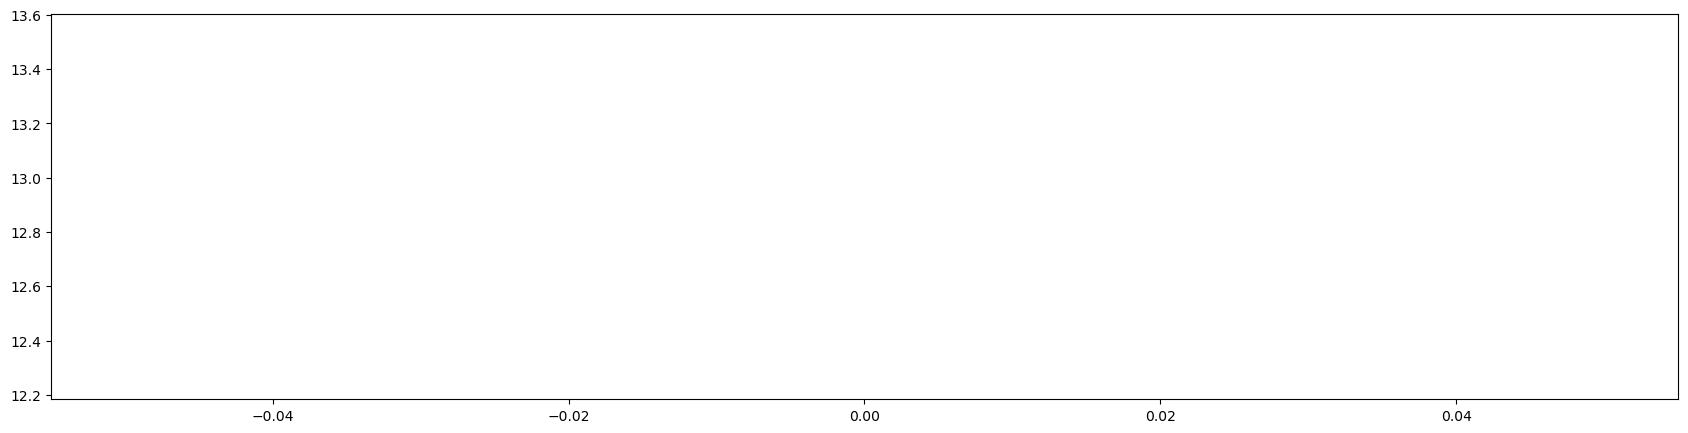

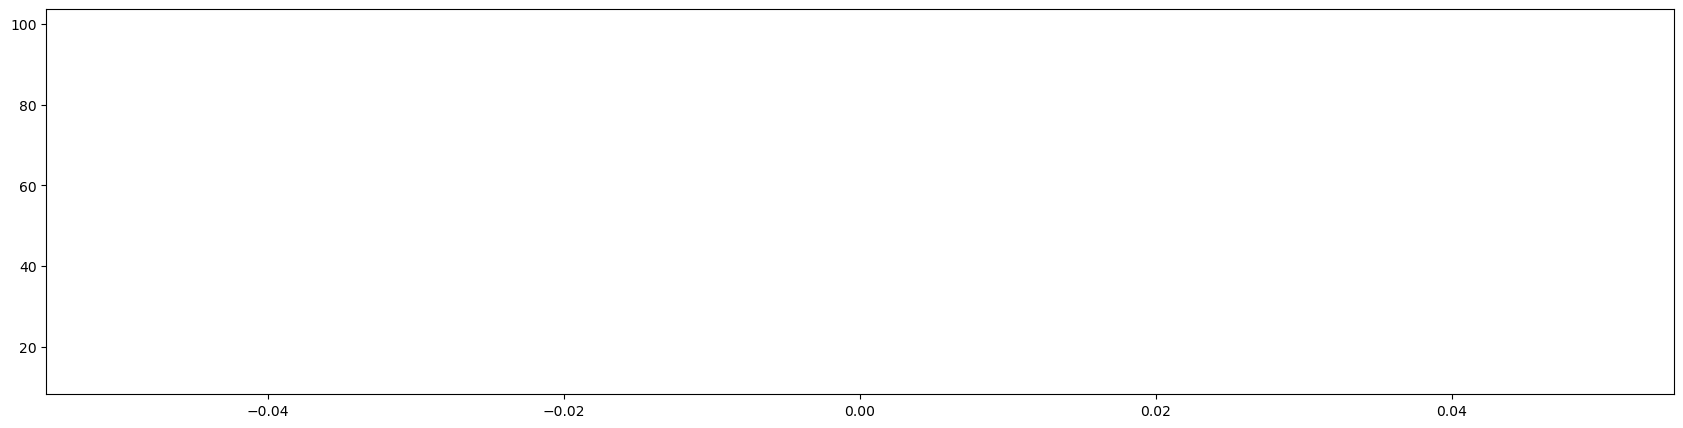

In [1518]:
ms = list()
losses = list()
for row in s:
    w = row[0]
    losses.append(row[1])
    hw = pd.read_csv(train_data + f"/{w}__horizontal_well.csv")    
    m = np.isnan(hw['TVT_input'].values)
    e = hw[m]
    m, c = np.polyfit(e['MD'], e['Z'], deg=1)
    z = e['Z'] - e['Z'].iloc[0] - m * e['MD'] - c + e['TVT'] - e['TVT'].iloc[0] 
    ms.append(z.std())

plt.figure(figsize=(21, 5))
plt.plot(ms)
plt.figure(figsize=(21, 5))
plt.plot(losses)

In [ ]:
np.corrcoef(ms, losses)[0, 1]

## Making data for predicting the correct hypterparameters for the physics pipeline

In [113]:
import itertools
import numpy as np
import pandas as pd
from tqdm import tqdm

# 1. Define the parameter grid
param_grid = {
    'anchor_density': [3],
    'max_m_range': [0.05],
    'alpha': [0.0],
    'beta': [0, 100, 500, 1000],
    'max_m': [0.05],
    'gamma': [0, 1000, 5000, 10000]
}

# 2. Generate combinations and mappings
keys, values = zip(*param_grid.items())
combinations = [dict(zip(keys, v)) for v in itertools.product(*values)]

# Create column names like "Set_0", "Set_1" to keep the DataFrame readable
param_set_names = [f"Set_{i}" for i in range(len(combinations))]

# Create a mapping DataFrame so you can look up what "Set_3" actually means later
mapping_df = pd.DataFrame(combinations)
mapping_df.insert(0, 'Set_Name', param_set_names)
print("Parameter Set Mapping (First 5):")
print(mapping_df.head())
print("-" * 50)

# 3. Setup evaluation
# evaluation_wells = np.random.choice(well_names, size=, replace=False)
evaluation_wells = (well_names)
evaluation_wells = np.random.choice(well_names, size=300)
well_results = []

print(f"Evaluating {len(combinations)} parameter sets across {len(evaluation_wells)} wells...")

# Outer Loop: Iterate through wells
for well in tqdm(evaluation_wells, desc="Processing Wells", position=0):
    
    # Initialize the row dictionary for this well
    row_data = {'Well': well}
    
    # --- HEAVY LIFTING DONE ONCE PER WELL ---
    z, gr, tvt0, tw_gr, tw_tvt = pre_process(well)
    
    boundaries = np.linspace(0, len(z), 50).astype(int)
    num_chunks = len(boundaries) - 1
    
    # Load Ground Truth
    hw = pd.read_csv(train_data + f"/{well}__horizontal_well.csv")    
    mask = np.isnan(hw['TVT_input'].values)
    true_tvt = hw[mask]['TVT']
    # -----------------------------------------
    
    # Inner Loop: Test every parameter set on this single well
    for idx, params in enumerate(combinations):
        set_name = param_set_names[idx]
        
        # Update globals
        global anchor_density, max_m_range, alpha, beta, max_m, gamma
        anchor_density = params['anchor_density']
        max_m_range = params['max_m_range']
        alpha = params['alpha']
        beta = params['beta']
        max_m = params['max_m']
        gamma = params['gamma']
        
        # Run predictions
        optimal_m, optimal_anchors = find_ms(boundaries, z, gr, tvt0, tw_gr, tw_tvt) 
        optimal_pred_tvt = np.zeros(len(z))

        for i in range(num_chunks):
            start_idx = boundaries[i]
            end_idx = boundaries[i+1]
            chunk_len = end_idx - start_idx
            steps = np.arange(chunk_len)
            
            hypo_z_tvt = optimal_anchors[i] + (optimal_m[i] * steps)
            hypo_tvt = hypo_z_tvt + z[start_idx:end_idx] + tvt0
            optimal_pred_tvt[start_idx:end_idx] = hypo_tvt

        # Calculate Sum of Squared Errors (SSE)
        sse = np.sum((true_tvt - optimal_pred_tvt)**2)
        row_data[set_name] = sse
        
    well_results.append(row_data)

# 4. Finalize the DataFrame
results_df = pd.DataFrame(well_results)

# Find the column name (Set_X) that has the minimum SSE for each row
results_df['Best_Param_Set'] = results_df[param_set_names].idxmin(axis=1)

Parameter Set Mapping (First 5):
  Set_Name  anchor_density  max_m_range  alpha  beta  max_m  gamma
0    Set_0               3         0.05    0.0     0   0.05      0
1    Set_1               3         0.05    0.0     0   0.05   1000
2    Set_2               3         0.05    0.0     0   0.05   5000
3    Set_3               3         0.05    0.0     0   0.05  10000
4    Set_4               3         0.05    0.0   100   0.05      0
--------------------------------------------------
Evaluating 16 parameter sets across 300 wells...


Processing Wells: 100%|███████████████████████████████████████████████████████████████████████████████████████████████| 300/300 [1:59:29<00:00, 23.90s/it]


In [114]:
results_df.to_csv('../data/all_well_param_sets2.csv')

In [127]:
stats = list()
for well in results_df['Well']:
    h = pd.read_csv(f'../data/train/{well}__horizontal_well.csv')
    t = pd.read_csv(f'../data/train/{well}__typewell.csv')
    z, gr, tvt0, tw_gr, tw_tvt = pre_process(well)
    z = h[h['TVT_input'].isna()]['Z']
    gr = h[h['TVT_input'].isna()]['GR']
    stat = [well, len(z), z.std(), z.mean(), z.max() - z.min(), gr.std(), gr.mean(), gr.max() - gr.min(), tvt0]
    stats.append(stat)

stats[0]

[np.str_('c47e0767'),
 4356,
 31.890625760659457,
 np.float64(-9973.46462121212),
 108.72999999999956,
 9.525666633247123,
 np.float64(73.9146958948846),
 50.24384530189241,
 np.float64(12153.58)]

In [128]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Convert stats list to a DataFrame
stats_cols = ['Well', 'len_z', 'z_std', 'z_mean', 'z_range', 'gr_std', 'gr_mean', 'gr_range', 'tvt0']
stats_df = pd.DataFrame(stats, columns=stats_cols)

# 2. Merge with your results DataFrame
# Assuming results_df has a 'Well' column and a 'Best_Param_Set' column
analysis_df = pd.merge(stats_df, results_df[['Well', 'Best_Param_Set']], on='Well')

In [129]:
stats_df.head()

,Well,len_z,z_std,z_mean,z_range,gr_std,gr_mean,gr_range,tvt0
0,c47e0767,4356,31.890626,-9973.464621,108.73,9.525667,73.914696,50.243845,12153.58
1,42669188,4282,46.059197,-9255.998517,183.24,15.965603,47.886394,93.280150,11623.16
2,b7fea9ef,3866,47.159326,-8764.419351,167.37,12.630460,93.807116,70.026665,10769.62
3,05a0ee4d,4348,56.942057,-9356.019890,191.40,16.272927,101.065954,118.440334,11927.50
4,05948241,3879,45.584207,-8608.386803,154.62,16.359423,81.313867,82.816710,10837.56


In [130]:
analysis_df.to_csv('../data/param_analysis_all2.csv')

In [131]:
analysis_df.head()

,Well,len_z,z_std,z_mean,z_range,gr_std,gr_mean,gr_range,tvt0,Best_Param_Set
0,c47e0767,4356,31.890626,-9973.464621,108.73,9.525667,73.914696,50.243845,12153.58,Set_8
1,c47e0767,4356,31.890626,-9973.464621,108.73,9.525667,73.914696,50.243845,12153.58,Set_8
2,c47e0767,4356,31.890626,-9973.464621,108.73,9.525667,73.914696,50.243845,12153.58,Set_8
3,42669188,4282,46.059197,-9255.998517,183.24,15.965603,47.886394,93.280150,11623.16,Set_3
4,b7fea9ef,3866,47.159326,-8764.419351,167.37,12.630460,93.807116,70.026665,10769.62,Set_0


In [132]:
import pandas as pd
import itertools

# 1. Recreate your parameter grid
param_grid = {
    'anchor_density': [3],
    'max_m_range': [0.05],
    'alpha': [0.0],
    'beta': [0, 100, 500, 1000],
    'max_m': [0.03, 0.05, 0.07],
    'gamma': [0, 500, 1000]
}

param_grid = {
    'anchor_density': [3],
    'max_m_range': [0.05],
    'alpha': [0.0],
    'beta': [0, 100, 500, 1000],
    'max_m': [0.05],
    'gamma': [0, 1000, 5000, 10000]
}

# 2. Rebuild the combinations mapping
keys, values = zip(*param_grid.items())
combinations = [dict(zip(keys, v)) for v in itertools.product(*values)]

# Create a mapping DataFrame
mapping_df = pd.DataFrame(combinations)
mapping_df['Set_Name'] = [f"Set_{i}" for i in range(len(combinations))]

# 3. Merge the actual parameters into your analysis_df
# (This assumes your dataframe is named 'analysis_df' and has the 'Best_Param_Set' column)
final_df = analysis_df.merge(
    mapping_df[['Set_Name', 'beta', 'max_m', 'gamma']], # Only bring over the target variables
    left_on='Best_Param_Set', 
    right_on='Set_Name', 
    how='left'
)

# 4. Drop the Set labels to achieve your target format: [stats, beta, max_m, gamma]
final_df = final_df.drop(columns=['Best_Param_Set', 'Set_Name'])

print(final_df.head())

       Well  len_z      z_std       z_mean  z_range     gr_std    gr_mean  \
0  c47e0767   4356  31.890626 -9973.464621   108.73   9.525667  73.914696   
1  c47e0767   4356  31.890626 -9973.464621   108.73   9.525667  73.914696   
2  c47e0767   4356  31.890626 -9973.464621   108.73   9.525667  73.914696   
3  42669188   4282  46.059197 -9255.998517   183.24  15.965603  47.886394   
4  b7fea9ef   3866  47.159326 -8764.419351   167.37  12.630460  93.807116   

    gr_range      tvt0  beta  max_m  gamma  
0  50.243845  12153.58   500   0.05      0  
1  50.243845  12153.58   500   0.05      0  
2  50.243845  12153.58   500   0.05      0  
3  93.280150  11623.16     0   0.05  10000  
4  70.026665  10769.62     0   0.05      0  


In [133]:
final_df.to_csv('../data/hyperparams_physics_wells2.csv')

In [136]:
count = 0
for well in results_df['Well']:
    h = pd.read_csv(f'../data/train/{well}__horizontal_well.csv')
    e = h[h['TVT_input'].isna()]
    count += len(e)

In [146]:
for i in range(16):
    print(np.sqrt(results_df[f'Set_{i}'].sum() / count))

11.494391216736444
11.425357510267906
11.457600902534361
11.784539594336781
11.49313113058183
11.434733579106902
11.45863835248142
11.78475173237692
11.491886809003056
11.436868900278244
11.452972651796975
11.792296301202663
11.454184163696006
11.607843028872594
11.435950552091573
11.791601497740746
